# 1. Import

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from tqdm import tqdm
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss

import warnings
warnings.filterwarnings("ignore")

In [2]:
# Custom plotting style
plt.style.use('default')

plt.rcParams.update({
    # === Canvas ===
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'axes.edgecolor': '#d0d0d0',
    'axes.linewidth': 1.0,

    # === Typography ===
    'font.family': 'sans-serif',
    'font.sans-serif': [
        'Calibri', 'Helvetica Neue', 'DejaVu Sans',
        'Helvetica', 'Liberation Sans', 'Verdana'
    ],
    'font.size': 12,              # Base
    'axes.labelsize': 13,         # Axis labels > base
    'axes.titlesize': 14,         # Title > labels
    'axes.titleweight': 'semibold',
    'axes.titlepad': 8,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'legend.fontsize': 11,
    'legend.frameon': False,
    'legend.loc': 'upper left',

    # === Grid ===
    'grid.color': '#f4f4f4',          # Ultra-light gray
    'grid.linewidth': 0.5,
    'grid.linestyle': '-',            # Solid line feels more modern
    'axes.grid': True,
    'axes.axisbelow': True,

    # === Spines ===
    'axes.spines.left': True,
    'axes.spines.bottom': True,
    'axes.spines.top': False,
    'axes.spines.right': False,

    # === Color Cycle: Modern, vibrant, accessible ===
    'axes.prop_cycle': plt.cycler(
        'color',
        [
            '#0055A4',  # Deep Blue
            '#E67E22',  # Warm Orange
            '#27AE60',  # Emerald Green
            '#8E44AD',  # Royal Purple
            '#D35400',  # Pumpkin
            '#3498DB',  # Bright Blue
            '#16A085',  # Turquoise
            '#F39C12',  # Golden Yellow
            '#9B59B6',  # Soft Purple
            '#C0392B',  # Brick Red
        ]
    ),
})

In [3]:
url = (
    "https://raw.githubusercontent.com/marcopeix/"
    "youtube_tutorials/refs/heads/main/data/"
    "daily_sales_french_bakery.csv"
)

df = pd.read_csv(url, parse_dates=["ds"])
df.shape

(57046, 4)

In [4]:
# df.to_csv('daily_sales_french_bakery.csv', index=False)

In [5]:
df.head()

,unique_id,ds,y,unit_price
0,12 MACARON,2022-07-13,10.0,10.0
1,12 MACARON,2022-07-14,0.0,10.0
2,12 MACARON,2022-07-15,0.0,10.0
3,12 MACARON,2022-07-16,10.0,10.0
4,12 MACARON,2022-07-17,30.0,10.0


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 57046 entries, 0 to 57045
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   unique_id   57046 non-null  object        
 1   ds          57046 non-null  datetime64[ns]
 2   y           57046 non-null  float64       
 3   unit_price  57046 non-null  float64       
dtypes: datetime64[ns](1), float64(2), object(1)
memory usage: 1.7+ MB


In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df_check = df.copy()
df_check['BASE'] = 1

df_check.groupby(['BASE']).agg(
    cnt_product=('unique_id', 'nunique'),
    min_date=('ds', 'min'),
    max_date=('ds', 'max')
).reset_index()

,BASE,cnt_product,min_date,max_date
0,1,148,2021-01-02,2022-09-30


In [9]:
df_temp = df_check.groupby('unique_id')['y'].sum().reset_index()
df_temp.sort_values('y', ascending=False).head(10)

,unique_id,y
139,TRADITIONAL BAGUETTE,144756.05
56,FORMULE SANDWICH,34710.50
31,CROISSANT,33579.50
84,PAIN AU CHOCOLAT,31100.45
6,BANETTE,24555.15
3,BAGUETTE,20481.40
122,SANDWICH COMPLET,13550.00
125,SPECIAL BREAD,13419.70
140,TRAITEUR,12254.30
71,GRAND FAR BRETON,10713.50


In [10]:
# Prep data
product_obs = ["BAGUETTE"]
data = (
    df[df["unique_id"].isin(product_obs)]  # small df for exercise
    .sort_values("ds")
    .copy()
    .reset_index(drop=True)
)
print(f"Data shape for products observed ({product_obs}): {data.shape}")

data.head()

Data shape for products observed (['BAGUETTE']): (637, 4)


,unique_id,ds,y,unit_price
0,BAGUETTE,2021-01-02,41.4,0.9
1,BAGUETTE,2021-01-03,31.5,0.9
2,BAGUETTE,2021-01-04,27.0,0.9
3,BAGUETTE,2021-01-05,26.1,0.9
4,BAGUETTE,2021-01-06,0.0,0.9


In [11]:
data = data[["ds", "y"]].copy()
data = data.set_index("ds")
data.shape

(637, 1)

In [12]:
data.head()

,y
ds,
2021-01-02,41.4
2021-01-03,31.5
2021-01-04,27.0
2021-01-05,26.1
2021-01-06,0.0


# 2. EDA

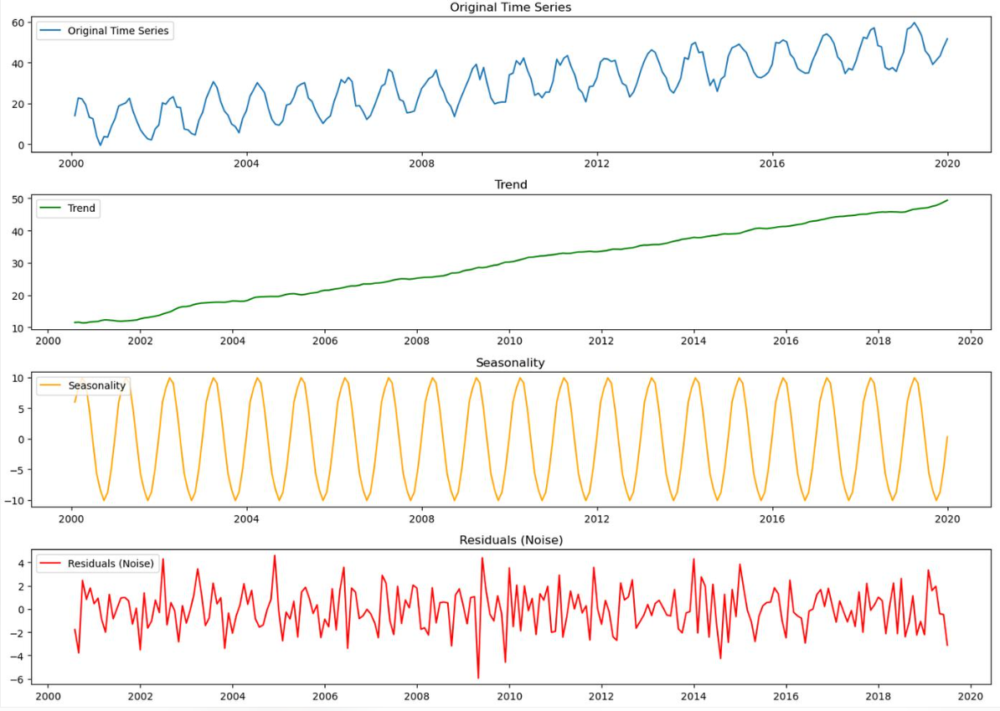

What to check:
- Trend, seasonality, cyclicality and residuals.
- Autocorrelation (ACF) and partial autocorrelation (PACF).
- Stationarity and differencing.
- Time frequency: daily, weekly, monthly.

**Checks**
- STL: Helps us understand the components of the time series.
- ACF/PACF: Helps us understand temporal dependencies.
- ADF/KPSS: Helps us statistically investigate stationarity.
- Differencing: Transforms the series to address non-stationarity.
- ARIMA: Uses these properties to construct a forecasting model.

## 2.1 Metadata Definition

In [13]:
data_orig = data.copy()
data_orig.shape

(637, 1)

In [14]:
# define params
col_target = "y"
col_time = "ds"

In [15]:
print("Start date:", data.index.min())
print("End date:", data.index.max())

print("Total calendar days:",
      (data.index.max() - data.index.min()).days + 1)

print("Total observations:", len(data))

print("Missing dates:", 
      len(pd.date_range(
          start=data.index.min(),
          end=data.index.max(),
          freq="D"
      ).difference(data.index)))

Start date: 2021-01-02 00:00:00
End date: 2022-09-30 00:00:00
Total calendar days: 637
Total observations: 637
Missing dates: 0


## 2.2 Time Series Visualization

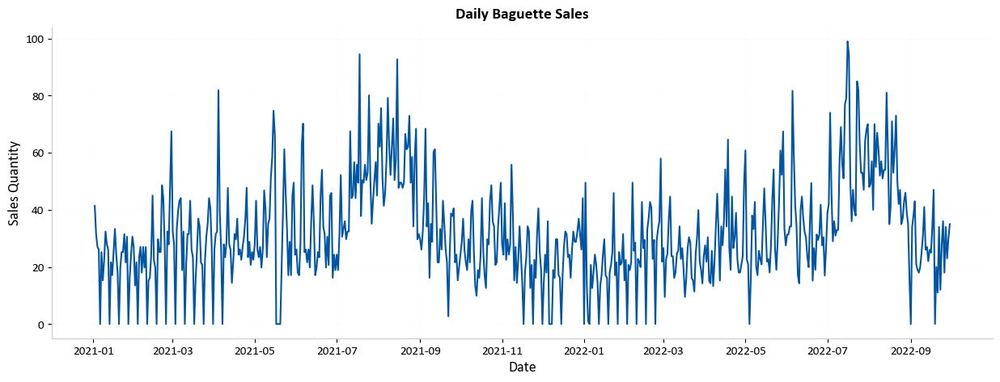

In [16]:
plt.figure(figsize=(15, 5))

plt.plot(data.index, data[col_target])

plt.title("Daily Baguette Sales")
plt.xlabel("Date")
plt.ylabel("Sales Quantity")

plt.grid(alpha=0.3)
plt.show()

In [17]:
# Check data frequency and continuity
print("Duplicate dates:", data.index.duplicated().sum())

date_range = pd.date_range(
    start=data.index.min(),
    end=data.index.max(),
    freq="D"
)

missing_dates = date_range.difference(data.index)

print("Missing dates:", len(missing_dates))
print("Expected observations:", len(date_range))
print("Actual observations:", len(data))

Duplicate dates: 0
Missing dates: 0
Expected observations: 637
Actual observations: 637


## 2.3 Descriptive Statistics

In [18]:
# Basic descriptive statistics
data[col_target].describe()

count    637.000000
mean      32.152904
std       17.509445
min        0.000000
25%       21.600000
50%       28.800000
75%       42.300000
max       99.000000
Name: y, dtype: float64

In [19]:
print("Mean:", data[col_target].mean())
print("Median:", data[col_target].median())
print("Std:", data[col_target].std())
print("Skewness:", data[col_target].skew())
print("Kurtosis:", data[col_target].kurtosis())

print("Zero sales:", (data[col_target] == 0).sum())
print("Zero sales percentage:", (data[col_target] == 0).mean() * 100)

Mean: 32.152904238618525
Median: 28.8
Std: 17.509444537125585
Skewness: 0.7368661096241028
Kurtosis: 0.9416357007912075
Zero sales: 37
Zero sales percentage: 5.808477237048666


## 2.4 Temporal Pattern Analysis

### 2.4.1 Weekly Seasonality

*Why is this important?*

Suppose Sunday consistently has zero sales.

That tells us:
- There may be a weekly business closure.
- A seasonal naive model with period 7 days might be useful.
- Day-of-week could be an important ML predictor.

In [20]:
data["day_of_week"] = data.index.dayofweek

weekday_stats = (
    data.groupby("day_of_week")[col_target]
    .agg(["count", "mean", "median", "std", "min", "max"])
)

weekday_stats.index = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_stats

,count,mean,median,std,min,max
Monday,91,30.853297,26.10,15.029949,0.0,69.0
Tuesday,91,28.157143,26.10,12.932050,0.0,75.6
Wednesday,91,19.200549,18.00,17.872085,0.0,62.1
Thursday,91,28.185714,25.20,13.726176,0.0,77.0
Friday,91,30.564286,27.00,13.412184,12.0,79.0
Saturday,91,38.347253,35.15,15.308056,0.0,99.0
Sunday,91,49.762088,45.60,17.118830,24.3,94.5


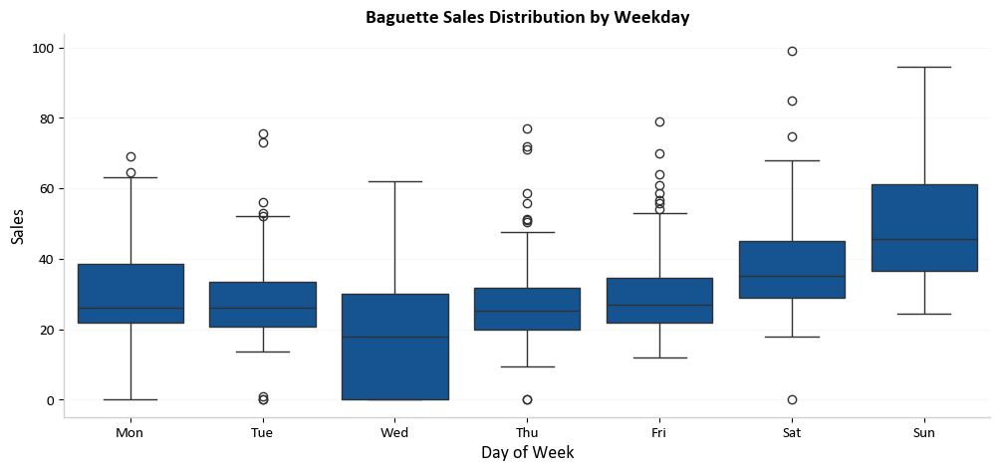

In [21]:
plt.figure(figsize=(12, 5))

sns.boxplot(
    data=data,
    x="day_of_week",
    y=col_target
)

plt.xticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])

plt.title("Baguette Sales Distribution by Weekday")
plt.xlabel("Day of Week")
plt.ylabel("Sales")

plt.show()

### 2.4.2 Zero Sales Analysis

In [22]:
zero_analysis = (
    data.groupby("day_of_week")[col_target]
    .apply(lambda x: (x == 0).mean() * 100)
)

zero_analysis.index = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

print(zero_analysis)

Monday        3.296703
Tuesday       2.197802
Wednesday    31.868132
Thursday      2.197802
Friday        0.000000
Saturday      1.098901
Sunday        0.000000
Name: y, dtype: float64


In [23]:
zero_analysis = (
    data.groupby(data.index.day_name())["y"]
    .agg(
        total_days="count",
        zero_sales=lambda x: (x == 0).sum()
    )
)

zero_analysis["zero_pct"] = (
    zero_analysis["zero_sales"] /
    zero_analysis["total_days"] * 100
)

zero_analysis

,total_days,zero_sales,zero_pct
ds,,,
Friday,91,0,0.000000
Monday,91,3,3.296703
Saturday,91,1,1.098901
Sunday,91,0,0.000000
Thursday,91,2,2.197802
Tuesday,91,2,2.197802
Wednesday,91,29,31.868132


In [24]:
wed = data.loc[data.index.dayofweek == 2, "y"]

print(f"Mean including zeros: {wed.mean():.2f}")
print(f"Mean excluding zeros: {wed[wed > 0].mean():.2f}")
print(f"Zero percentage: {(wed == 0).mean() * 100:.2f}%")

Mean including zeros: 19.20
Mean excluding zeros: 28.18
Zero percentage: 31.87%


In [25]:
date_analysis = (
    data.assign(
        weekday=data.index.day_name(),
        sales_status=np.where(data["y"] == 0, "Zero", "Positive")
    )
    .groupby(["weekday", "sales_status"])["y"]
    .agg(
        count="count",
        min_date=lambda x: x.index.min(),
        max_date=lambda x: x.index.max()
    )
)
date_analysis

count   min_date   max_date
weekday   sales_status                             
Friday    Positive         91 2021-01-08 2022-09-30
Monday    Positive         88 2021-01-04 2022-09-26
          Zero              3 2021-05-17 2022-09-19
Saturday  Positive         90 2021-01-02 2022-09-24
          Zero              1 2022-01-01 2022-01-01
Sunday    Positive         91 2021-01-03 2022-09-25
Thursday  Positive         89 2021-01-07 2022-09-29
          Zero              2 2021-05-20 2022-09-01
Tuesday   Positive         89 2021-01-05 2022-09-27
          Zero              2 2021-05-18 2021-12-07
Wednesday Positive         62 2021-04-14 2022-09-28
          Zero             29 2021-01-06 2022-05-04

In [26]:
# check zero sales by week of month
wed = data[data.index.dayofweek == 2].copy()

wed["week_of_month"] = ((wed.index.day - 1) // 7) + 1
wed["is_zero"] = (wed["y"] == 0).astype(int)

weekly_zero_analysis = (
    wed.groupby("week_of_month")
    .agg(
        total_days=("y", "count"),
        zero_sales=("is_zero", "sum"),
        avg_sales=("y", "mean")
    )
)

weekly_zero_analysis["zero_pct"] = (
    weekly_zero_analysis["zero_sales"] /
    weekly_zero_analysis["total_days"] * 100
)

weekly_zero_analysis

,total_days,zero_sales,avg_sales,zero_pct
week_of_month,,,,
1,21,8,19.080952,38.095238
2,21,6,22.538095,28.571429
3,21,8,17.414286,38.095238
4,21,6,18.790476,28.571429
5,7,1,16.135714,14.285714


In [27]:
wed["month"] = wed.index.to_period("M")

monthly_zero_analysis = (
    wed.pivot_table(
        index="month",
        columns="week_of_month",
        values="is_zero",
        aggfunc="sum",
        fill_value=0
    )
)

monthly_zero_analysis

week_of_month,1,2,3,4,5
month,,,,,
2021-01,1,1,1,1,0
2021-02,1,1,1,1,0
2021-03,1,1,1,1,1
2021-04,1,0,0,0,0
2021-05,0,0,1,0,0
2021-06,0,0,0,0,0
2021-07,0,0,0,0,0
2021-08,0,0,0,0,0
2021-09,0,0,0,0,0


No real pattern to explain why Wednesday zero sales are higher than the other days. It occurs randomly (clearly not store closure time).

### 2.4.3 Monthly Sales Trends

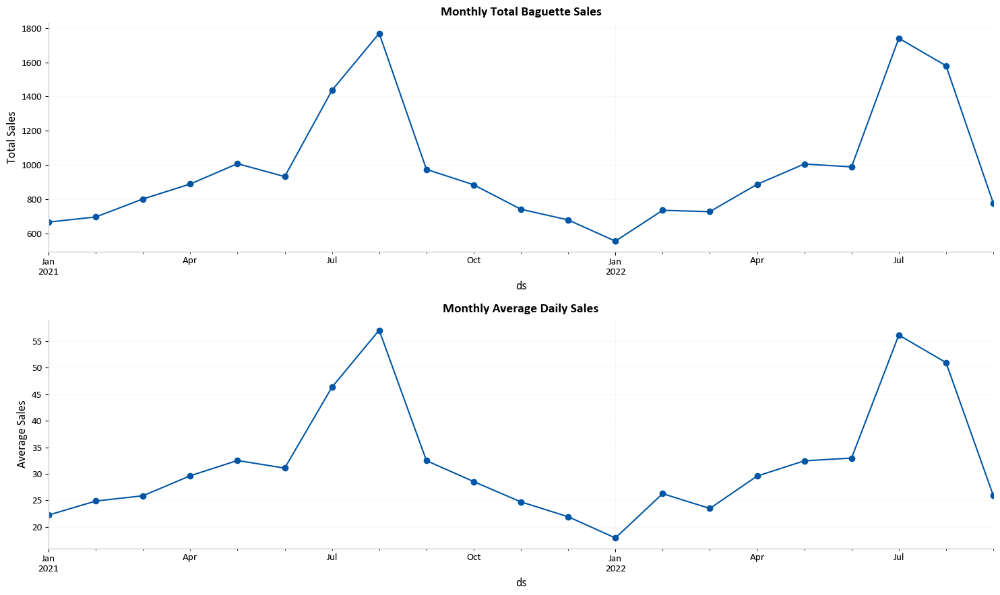

In [28]:
# Check each month's Wednesday pattern
monthly_sales = data[col_target].resample("MS").agg(
    ["sum", "mean", "median", "std"]
)

fig, axes = plt.subplots(2, 1, figsize=(15, 9))

monthly_sales["sum"].plot(
    ax=axes[0],
    marker="o"
)

axes[0].set_title("Monthly Total Baguette Sales")
axes[0].set_ylabel("Total Sales")

monthly_sales["mean"].plot(
    ax=axes[1],
    marker="o"
)

axes[1].set_title("Monthly Average Daily Sales")
axes[1].set_ylabel("Average Sales")

plt.tight_layout()
plt.show()

### 2.4.4 Monthly Seasonality

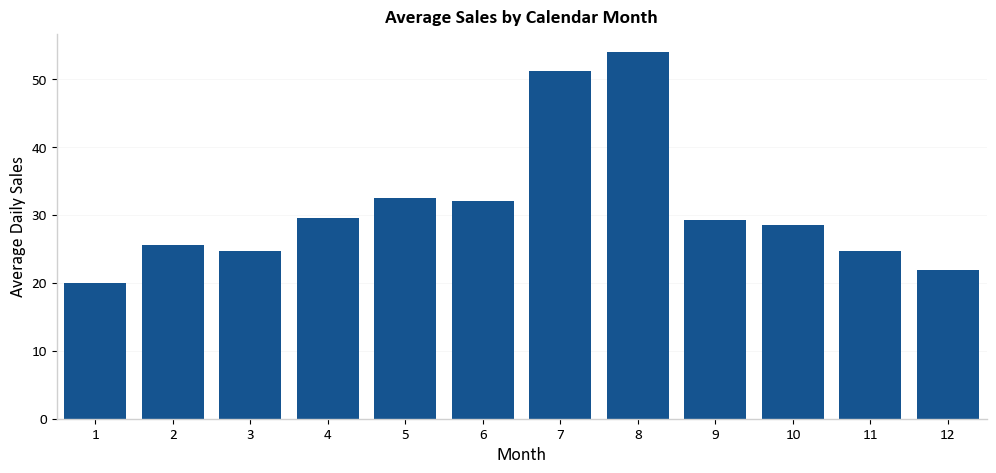

In [29]:
data["month"] = data.index.month

monthly_pattern = data.groupby("month")[col_target].mean()

plt.figure(figsize=(12, 5))

sns.barplot(
    x=monthly_pattern.index,
    y=monthly_pattern.values
)

plt.title("Average Sales by Calendar Month")
plt.xlabel("Month")
plt.ylabel("Average Daily Sales")

plt.show()

## 2.5 Time Series Decomposition (STL) - Trend, Seasonality, Residual

Separate the observed series into:
\[
Y_t = Trend_t + Seasonal_t + Residual_t
\]

Understand what is driving the sales fluctuations.

**There are two common decomposition approaches.**

Additive decomposition
\[
Y_t = T_t + S_t + R_t
\]:

Used when seasonal fluctuations are relatively constant in magnitude.

Multiplicative decomposition
\[
Y_t = T_t \times S_t \times R_t
\]:

Used when seasonal fluctuations change proportionally with the overall level.

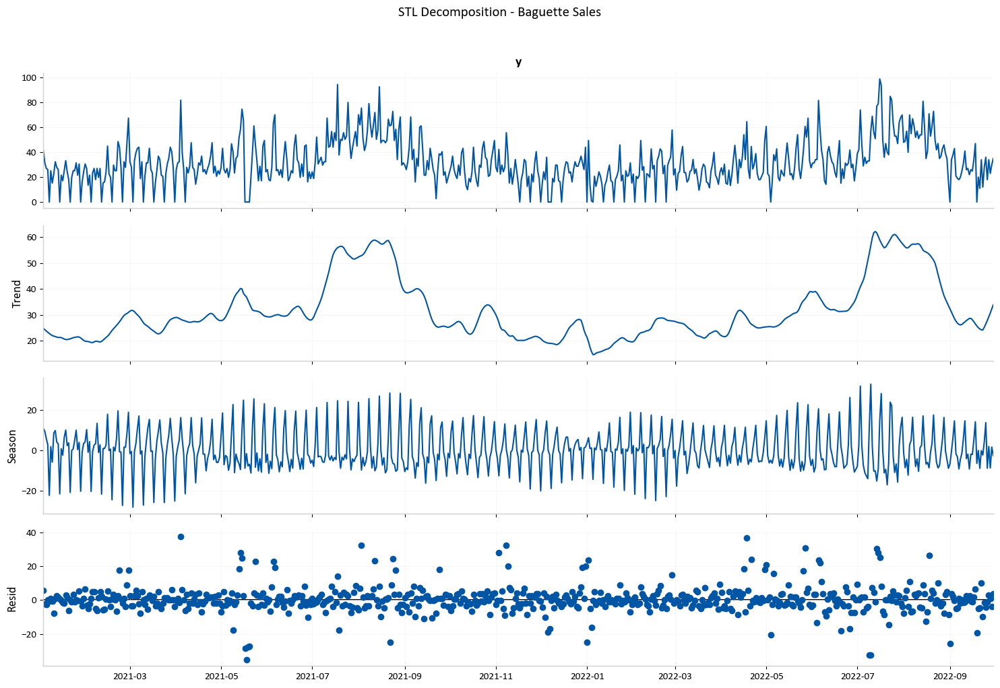

In [30]:
from statsmodels.tsa.seasonal import STL

# STL decomposition
stl = STL(
    data[col_target],
    period=7,
    robust=True
)

result = stl.fit()

# Plot decomposition
fig = result.plot()
fig.set_size_inches(15, 10)

plt.suptitle(
    "STL Decomposition - Baguette Sales",
    fontsize=15,
    y=1.02
)

plt.tight_layout()
plt.show()

**How to interpret the results**

Trend
- Does the trend increase or decrease?
- Are there periods of structural changes?
- Is the trend relatively stable?
  
Seasonal
- Are certain days consistently associated with higher or lower sales?
- Is the weekly pattern consistent throughout the dataset?
- Are weekends different from weekdays?
  
Residual
- Does it look like random noise?
- Are there remaining spikes?
- Is there still a visible pattern?

**Explanation**:
- Trend: fluctuate considerably, peak around Jul-Aug. Forecasting implications: A simple historical average may not adequately represent the current sales level. Investigate differencing, but should not automatically difference the series just because the STL trend moves. Differencing is a modeling decision that we will evaluate using additional evidence.
- Seasonal: Recurring fluctuations. Forecast implications: SARIMA with seasonal period 7, calendar features in ML, seasonal NAIVE with period 7
- Residual: Mostly centered around zero, but some exceeds +30 and -30. This suggests that our trend and weekly seasonal components do not explain all sales variation. Possible explanation: special events, unexpected demand spikes, missing business related predictors, structural changes, etc. Can add exogenous predictors.

## 2.6 Autocorrelation (ACF / PACF)

Autocorrelation measures how strongly a time series relates to its own previous observations. This will help us identify potential ARIMA parameters.

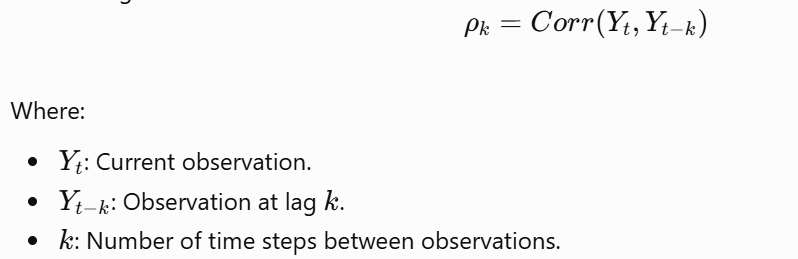

### 2.6.1 ACF

ACF measures the correlation between the series and its lagged values.

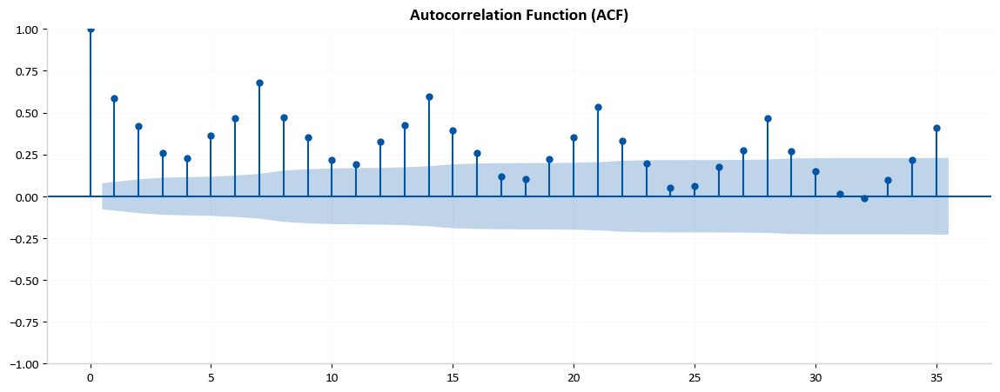

In [31]:
fig, ax = plt.subplots(figsize=(14, 5))

plot_acf(data[col_target], lags=35, ax=ax)

plt.title("Autocorrelation Function (ACF)")
plt.show()

If lag 7, 14, 21 and 28 show recurring significant spikes, this may indicate weekly seasonality.

### 2.6.2 PACF

PACF measures the direct relationship between the current observation and a particular lag, after accounting for the intermediate lags.

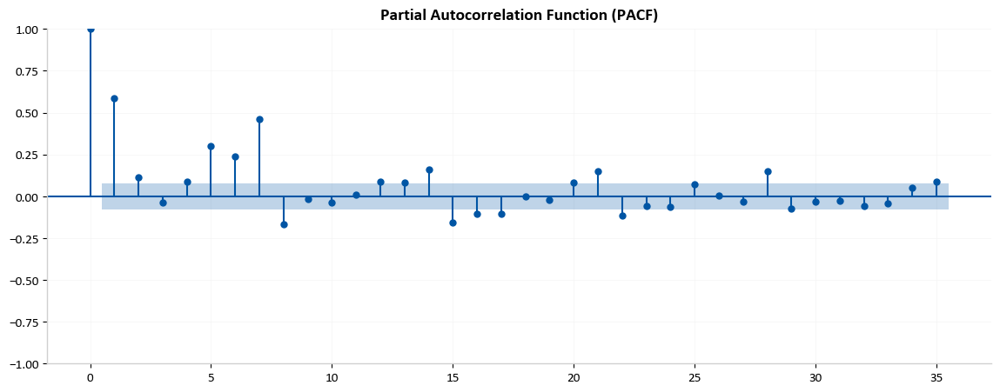

In [32]:
fig, ax = plt.subplots(figsize=(14, 5))

plot_pacf(data[col_target], lags=35, method="ywm", ax=ax)

plt.title("Partial Autocorrelation Function (PACF)")
plt.show()

PACF shows:
- Strong lag 1
- Significant positive values at some early lags, including 5–7.
- Most later lags are relatively small.

This suggests that recent observations contain direct predictive information.

**Important**: When a series is non-stationary, ACF and PACF patterns can be misleading. We should repeat these analyses after any necessary transformation.

## 2.7 Stationarity (ADF/KPSS)

Understand whether the statistical properties of the series change over time, and whether differencing is necessary.

In [33]:
from statsmodels.tsa.stattools import adfuller, kpss

def perform_adf_test(data):
    # Perform ADF test (add regression = 'ct' if you see a trend, and just leave regression 'c' if you don't)
    result = adfuller(data,regression='c', autolag='AIC')

    # Print the results
    print('p-value:', result[1])

    # Check if the data is stationary based on the p-value
    if result[1] <= 0.05:
        print("The data is stationary")
    else:
        print("The data is not stationary, Data can be processed further")

# Example Usage
perform_adf_test(data[col_target])

p-value: 0.12612534040025886
The data is not stationary, Data can be processed further


In [34]:
result = kpss(
    data[col_target],
    regression="c",
    nlags="auto"
)

print("KPSS Statistic:", result[0])
print("p-value:", result[1])

KPSS Statistic: 0.38505594268641125
p-value: 0.08359657642827101


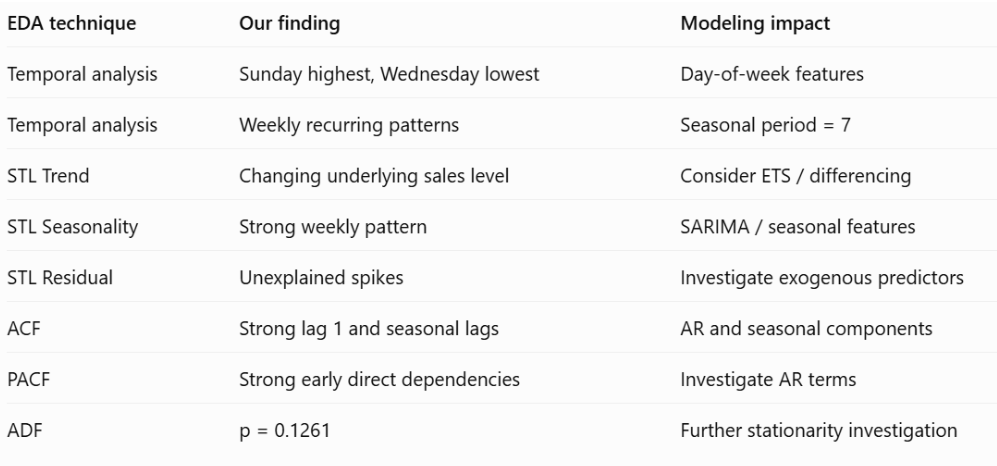

### 2.7.1 Differencing for Non-Stationary

Section to inspect non-stationarity (no need to run this is if data is stationary)

In [35]:
from statsmodels.tsa.stattools import adfuller, kpss

series = data[col_target]

transformations = {
    "Original": series,
    "First Difference": series.diff(),
    "Seasonal Difference (7)": series.diff(7),
    "First + Seasonal Difference": series.diff().diff(7)
}

for name, s in transformations.items():

    s = s.dropna()

    adf_p = adfuller(
        s,
        regression="c",
        autolag="AIC"
    )[1]

    kpss_p = kpss(
        s,
        regression="c",
        nlags="auto"
    )[1]

    print(f"\n{name}")
    print(f"ADF p-value: {adf_p:.4f}")
    print(f"KPSS p-value: {kpss_p:.4f}")


Original
ADF p-value: 0.1261
KPSS p-value: 0.0836

First Difference
ADF p-value: 0.0000
KPSS p-value: 0.1000

Seasonal Difference (7)
ADF p-value: 0.0000
KPSS p-value: 0.1000

First + Seasonal Difference
ADF p-value: 0.0000
KPSS p-value: 0.1000


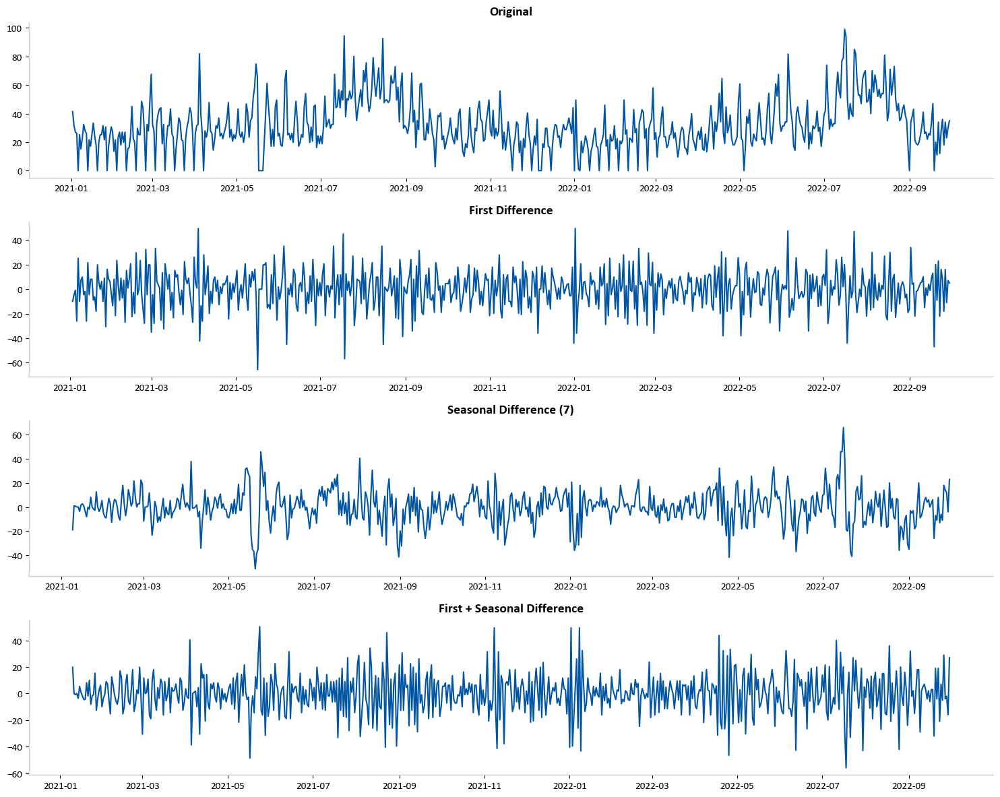

In [36]:
fig, axes = plt.subplots(
    4, 1,
    figsize=(15, 12)
)

for ax, (name, s) in zip(
    axes,
    transformations.items()
):

    ax.plot(s)
    ax.set_title(name)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

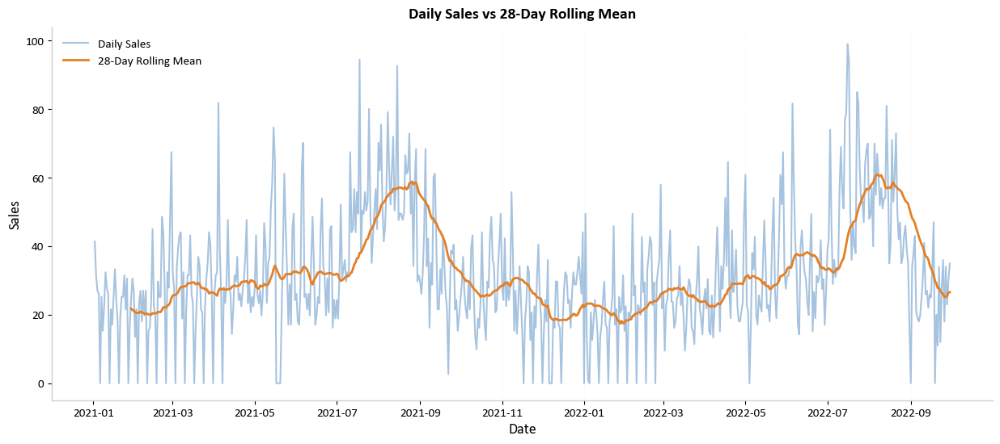

In [37]:
data_copy = data.copy()

data_copy["rolling_mean_28"] = data_copy[col_target].rolling(window=28).mean()

plt.figure(figsize=(15, 6))
plt.plot(
    data_copy.index,
    data_copy[col_target],
    alpha=0.35,
    label="Daily Sales"
)

plt.plot(
    data_copy.index,
    data_copy["rolling_mean_28"],
    linewidth=2,
    label="28-Day Rolling Mean"
)

plt.title("Daily Sales vs 28-Day Rolling Mean")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

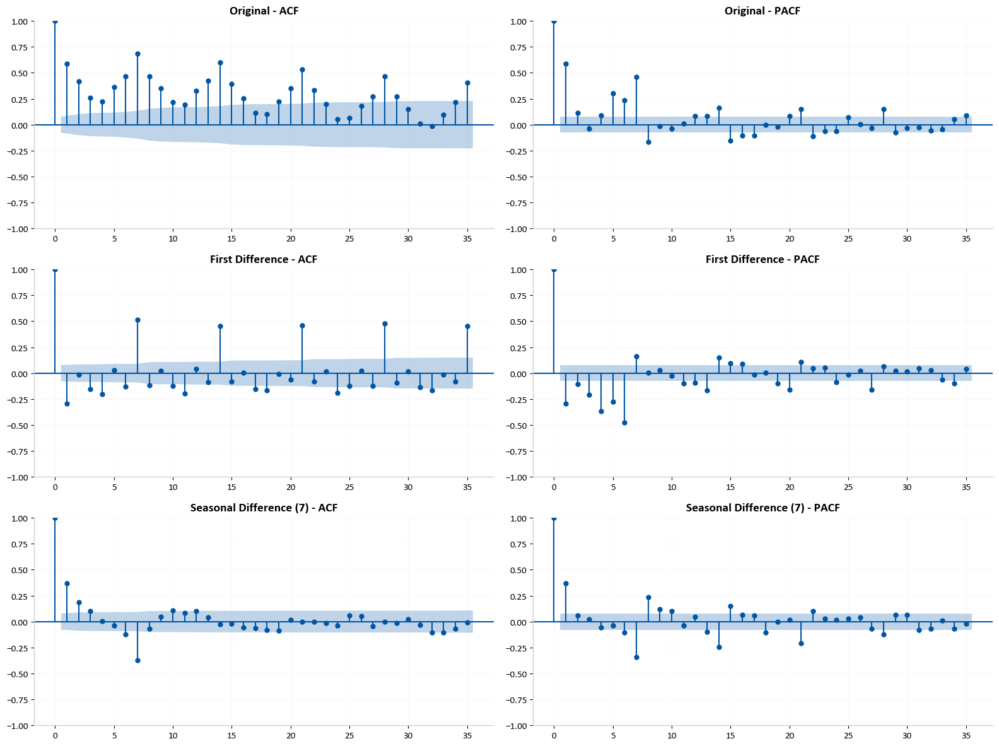

In [38]:
series_original = data[col_target]
series_diff1 = series_original.diff().dropna()
series_diff7 = series_original.diff(7).dropna()

fig, axes = plt.subplots(3, 2, figsize=(16, 12))

series_list = [
    ("Original", series_original),
    ("First Difference", series_diff1),
    ("Seasonal Difference (7)", series_diff7)
]

for i, (name, series) in enumerate(series_list):

    plot_acf(series, lags=35, ax=axes[i, 0])
    axes[i, 0].set_title(f"{name} - ACF")

    plot_pacf(series, lags=35, method="ywm", ax=axes[i, 1])
    axes[i, 1].set_title(f"{name} - PACF")

plt.tight_layout()
plt.show()

**How to Check**
- Does the ACF decay more quickly after differencing?
- Are the weekly spikes at 7, 14, 21 and 28 reduced?
- Does first differencing introduce strong negative autocorrelation at lag 1? A strong negative ACF spike at lag 1 after first differencing can sometimes indicate over-differencing, although it isn't conclusive by itself.
- Does seasonal differencing produce a cleaner autocorrelation structure?

**Interpretation**
- Original series: ADF p-value = 0.1261, KPSS = 0.0836. Stationarity is inconclusive at the 5% significance level.
- First differencing (d=1): Makes the series stationary according to ADF and KPSS, but weekly autocorrelation remains.
- Seasonal differencing (D=1, s=7): Makes the series stationary and substantially reduces weekly autocorrelation.
- First + seasonal differencing: Also produces stationarity, but may introduce unnecessary noise (over-differencing).

Final selection: *Seasonal differencing*
- Our weekday analysis identified strong weekly seasonality (Sunday sales highest, Wednesday lowest).
- ACF original showed repeated spikes at lags 7, 14, 21 and 28.
- Seasonal differencing compares sales with the same weekday from the previous week.
- After seasonal differencing, most repeated weekly ACF spikes disappeared.
- First differencing alone did not remove the weekly pattern.

## 2.8 Outlier Analysis

In [39]:
# Calculate IQR
Q1 = data[col_target].quantile(0.25)
Q2 = data[col_target].quantile(0.50)
Q3 = data[col_target].quantile(0.75)

IQR = Q3 - Q1

# Define outlier thresholds
lower_bound = Q1 - 3 * IQR
upper_bound = Q3 + 3 * IQR

# Identify outliers
outliers = data[
    (data[col_target] < lower_bound) |
    (data[col_target] > upper_bound)
].copy()

print(f"Q1: {Q1:.2f}")
print(f"Median: {Q2:.2f}")
print(f"Q3: {Q3:.2f}")
print(f"IQR: {IQR:.2f}")

print(f"Lower Bound: {lower_bound:.2f}")
print(f"Upper Bound: {upper_bound:.2f}")

print(f"Number of outliers: {len(outliers)}")
print(f"Outlier percentage: {len(outliers)/len(data)*100:.2f}%")

Q1: 21.60
Median: 28.80
Q3: 42.30
IQR: 20.70
Lower Bound: -40.50
Upper Bound: 104.40
Number of outliers: 0
Outlier percentage: 0.00%


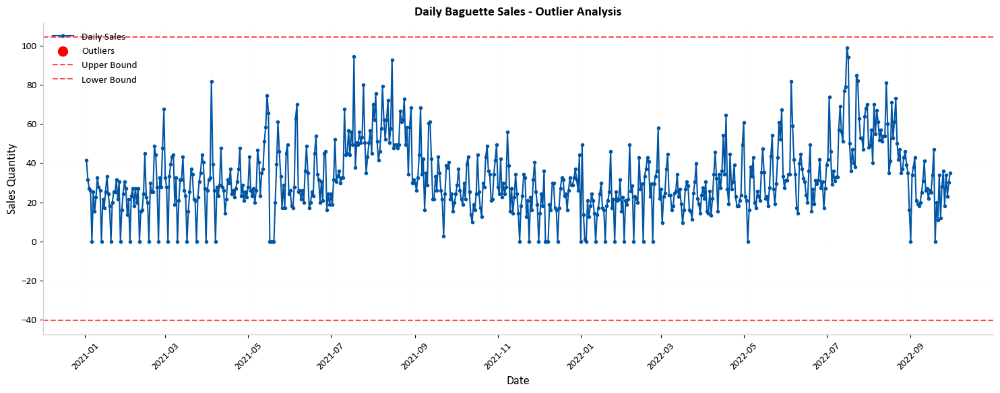

In [40]:
# Plot main data
plt.figure(figsize=(15, 6))

plt.plot(data.index, data["y"], marker="o", markersize=3, linestyle="-", label="Daily Sales")

# Highlight outliers
plt.scatter(outliers.index, outliers["y"], color="red", s=100, label="Outliers", zorder=3)

# Annotate outliers
for date, row in outliers.iterrows():
    plt.annotate(
        f"({date.strftime('%Y-%m-%d')}, {row['y']:.1f})",
        (date, row["y"]),
        textcoords="offset points",
        xytext=(5, 10),
        ha="left",
        fontsize=8,
        color="red"
    )

# Threshold lines
plt.axhline(upper_bound, color="red", linestyle="--", alpha=0.7, label="Upper Bound")
plt.axhline(lower_bound, color="red", linestyle="--", alpha=0.7, label="Lower Bound")

plt.xlabel("Date")
plt.ylabel("Sales Quantity")
plt.title("Daily Baguette Sales - Outlier Analysis")

plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 2.9 Selecting Initial Parameters for ARIMA/SARIMA

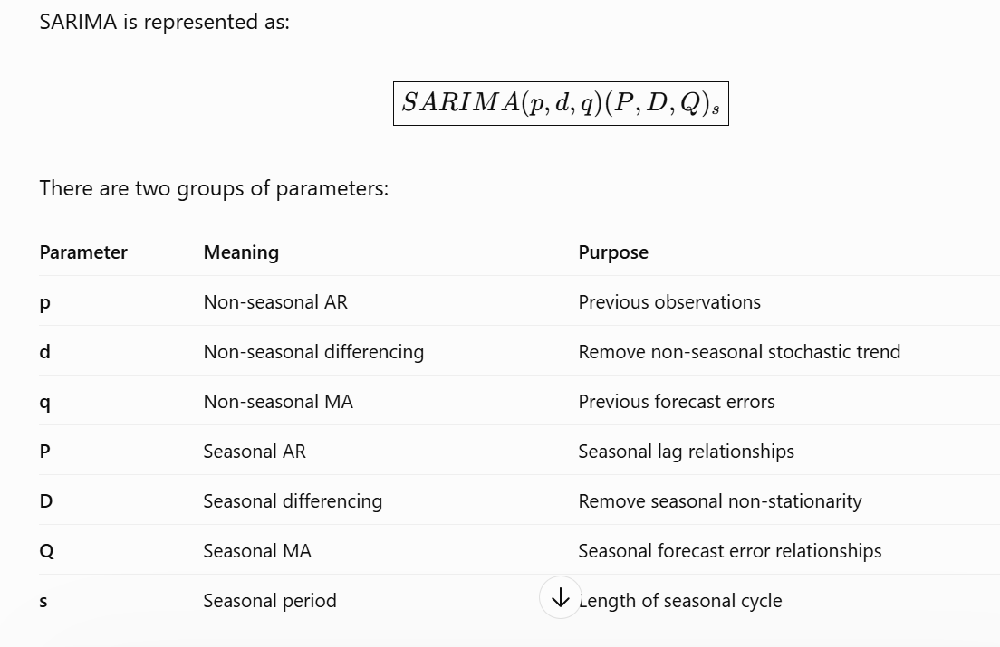

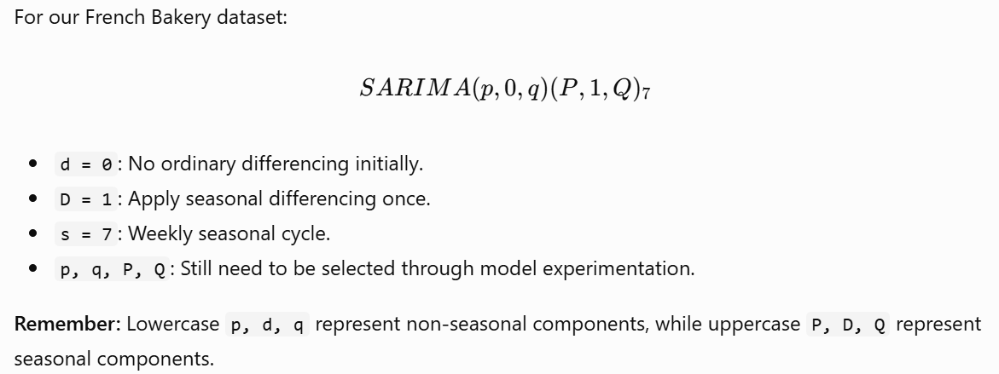

# 3. Data Splitting

## 3.1 Forecast Horizon Definition

In [41]:
data.head()

,y,day_of_week,month
ds,,,
2021-01-02,41.4,5,1
2021-01-03,31.5,6,1
2021-01-04,27.0,0,1
2021-01-05,26.1,1,1
2021-01-06,0.0,2,1


In [42]:
# Forecasting configuration
forecast_horizon = 90  
seasonal_period = 7    # weekly seasonality
test_period = forecast_horizon

In [43]:
637/7

91.0

## 3.2 Train / Test Split

In [44]:
# Determine test starting date
test_start = data.index.max() - pd.Timedelta(days=test_period - 1)

# Chronological split
train = data.loc[data.index < test_start].copy()
test = data.loc[data.index >= test_start].copy()
train.shape, test.shape

((547, 3), (90, 3))

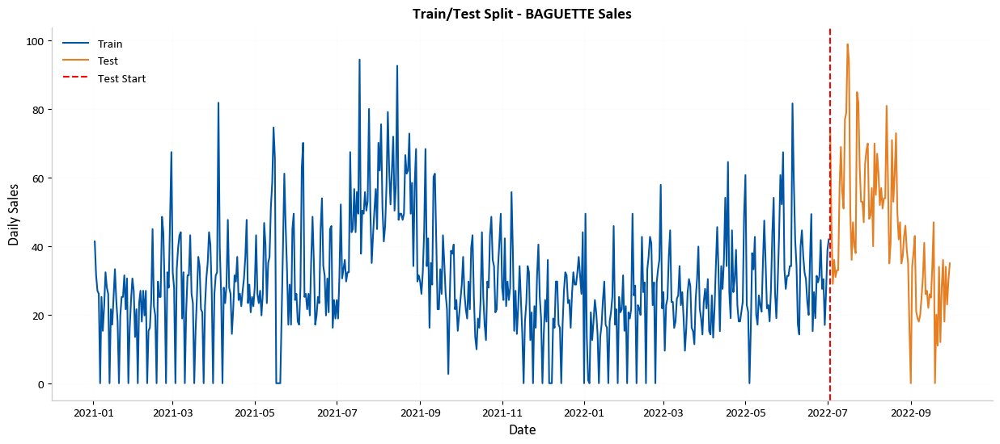

In [45]:
plt.figure(figsize=(15, 6))

plt.plot(train.index, train[col_target], label="Train")
plt.plot(test.index, test[col_target], label="Test")

plt.axvline(test.index.min(), color="red", linestyle="--", label="Test Start")

plt.title("Train/Test Split - BAGUETTE Sales")
plt.xlabel("Date")
plt.ylabel("Daily Sales")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [46]:
# Keep original training and test datasets
train_orig = train.copy()
test_orig = test.copy()
train_orig.shape, test_orig.shape

((547, 3), (90, 3))

## 3.3 Time Series Cross-Validation

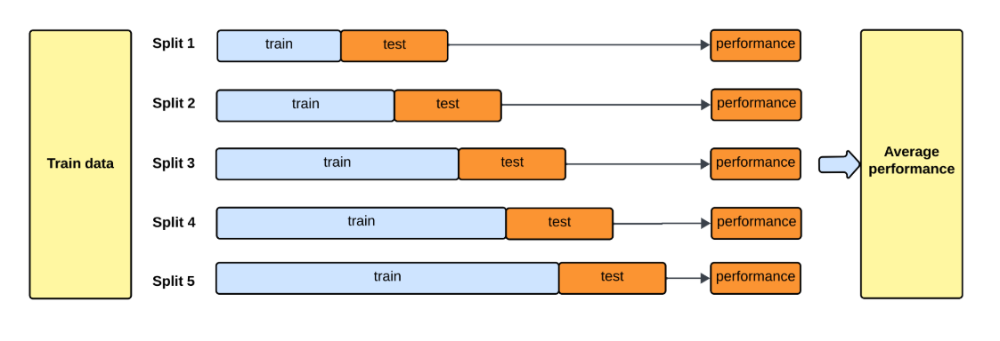

In [47]:
# define number of CV folds
cv_folds = 3

In [48]:
n_obs = train.shape[0]

initial_train_size = n_obs - (cv_folds * forecast_horizon)
step_size = forecast_horizon

print("Total training observations:", n_obs)
print("Initial training size:", initial_train_size)
print("CV folds:", cv_folds)
print("Validation horizon:", forecast_horizon)
print("Step size:", step_size)

Total training observations: 547
Initial training size: 277
CV folds: 3
Validation horizon: 90
Step size: 90


In [49]:
def create_expanding_splits(
    data,
    initial_train_size,
    horizon,
    step_size
):
    splits = []

    for train_end in range(
        initial_train_size,
        len(data) - horizon + 1,
        step_size
    ):
        train_fold = data.iloc[:train_end].copy()
        valid_fold = data.iloc[train_end:train_end + horizon].copy()

        splits.append({
            "train": train_fold,
            "valid": valid_fold
        })

    return splits

In [50]:
cv_splits = create_expanding_splits(
    data=train,
    initial_train_size=initial_train_size,
    horizon=forecast_horizon,
    step_size=step_size
)

print("Number of folds:", len(cv_splits))

Number of folds: 3


In [51]:
cv_summary = []

for i, fold in enumerate(cv_splits, start=1):

    train_fold = fold["train"]
    valid_fold = fold["valid"]

    cv_summary.append({
        "fold": i,
        "train_start": train_fold.index.min(),
        "train_end": train_fold.index.max(),
        "train_size": len(train_fold),
        "valid_start": valid_fold.index.min(),
        "valid_end": valid_fold.index.max(),
        "valid_size": len(valid_fold)
    })

cv_summary = pd.DataFrame(cv_summary)
cv_summary

,fold,train_start,train_end,train_size,valid_start,valid_end,valid_size
0,1,2021-01-02,2021-10-05,277,2021-10-06,2022-01-03,90
1,2,2021-01-02,2022-01-03,367,2022-01-04,2022-04-03,90
2,3,2021-01-02,2022-04-03,457,2022-04-04,2022-07-02,90


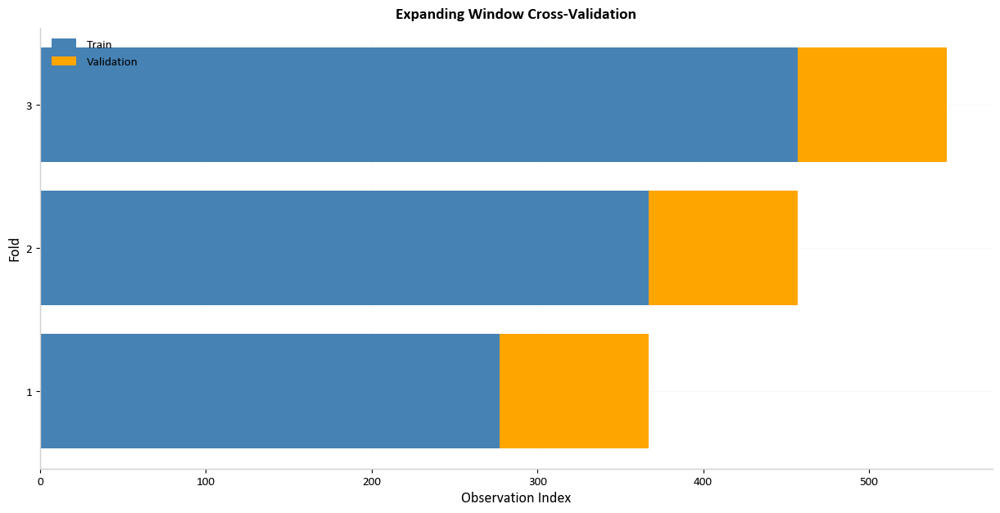

In [52]:
plt.figure(figsize=(15, 7))

for i, fold in enumerate(cv_splits, start=1):

    train_fold = fold["train"]
    valid_fold = fold["valid"]

    plt.barh(
        i,
        len(train_fold),
        left=0,
        color="steelblue",
        label="Train" if i == 1 else ""
    )

    plt.barh(
        i,
        len(valid_fold),
        left=len(train_fold),
        color="orange",
        label="Validation" if i == 1 else ""
    )

plt.yticks(range(1, len(cv_splits) + 1))

plt.xlabel("Observation Index")
plt.ylabel("Fold")
plt.title("Expanding Window Cross-Validation")

plt.legend()
plt.grid(axis="x", alpha=0.3)
plt.show()

# 4. Feature Engineering of Time

## 4.1 Exogenous Predictor

### 4.1.1 Day of Week, Month, Weekend

In [53]:
def create_calendar_features(
    data,
    date_col=None,
    drop_date_col=False
):
    """
    Generate calendar-based features from a DatetimeIndex
    or a specified datetime column.

    Parameters
    ----------
    data : pd.DataFrame
        Input dataframe.
    date_col : str, optional
        Datetime column. If None, uses the dataframe index.
    drop_date_col : bool, default False
        Whether to drop the original date column after feature creation.

    Returns
    -------
    pd.DataFrame
        Dataframe with calendar features.
    """
    
    df = data.copy()

    # Get datetime values
    dates = (
        pd.to_datetime(df[date_col])
        if date_col is not None
        else pd.to_datetime(df.index)
    )
    
    # Calendar features
    df["year"] = dates.year
    df["month"] = dates.month
    df["day"] = dates.day
    df["day_of_week"] = dates.dayofweek
    df["day_of_year"] = dates.dayofyear
    df["week_of_year"] = dates.isocalendar().week.to_numpy()
    df["quarter"] = dates.quarter
    
    # Weekend indicator
    df["is_weekend"] = (df["day_of_week"].isin([5, 6])).astype(int)

    # Payweek indicator
    df["is_payweek"] = ((dates.day >= 25) | (dates.day <= 5)).astype(int)

    # Month start / end indicators
    df["is_month_start"] = (dates.day <= 3).astype(int)
    df["is_month_end"] = (dates.day >= dates.days_in_month - 2).astype(int)

    # Cyclical encoding
    df["day_sin"] = np.sin(2 * np.pi * df["day_of_week"] / 7)
    df["day_cos"] = np.cos(2 * np.pi * df["day_of_week"] / 7)

    if date_col is not None and drop_date_col:
        df = df.drop(columns=date_col)
    
    return df

In [54]:
data = create_calendar_features(data)
data.shape

(637, 14)

In [55]:
data.head()

,y,day_of_week,month,year,day,day_of_year,week_of_year,quarter,is_weekend,is_payweek,is_month_start,is_month_end,day_sin,day_cos
ds,,,,,,,,,,,,,,
2021-01-02,41.4,5,1,2021,2,2,53,1,1,1,1,0,-0.974928,-0.222521
2021-01-03,31.5,6,1,2021,3,3,53,1,1,1,1,0,-0.781831,0.623490
2021-01-04,27.0,0,1,2021,4,4,1,1,0,1,0,0,0.000000,1.000000
2021-01-05,26.1,1,1,2021,5,5,1,1,0,1,0,0,0.781831,0.623490
2021-01-06,0.0,2,1,2021,6,6,1,1,0,0,0,0,0.974928,-0.222521


### 4.1.2 Public Holiday & Special Events

In [56]:
import holidays

def create_holiday_features(
    data,
    date_col=None,
    country="FR",
    subdiv=None,
    special_events=None,
    save_csv=True,
    output_path="holiday.csv"
):
    """
    Create public holiday and special event features.

    Parameters
    ----------
    data : pd.DataFrame
        Input dataframe.
    date_col : str, optional
        Datetime column. If None, uses DatetimeIndex.
    country : str, default "FR"
        Country code supported by holidays package.
    subdiv : str, optional
        Regional subdivision, if applicable.
    special_events : dict, optional
        Dictionary mapping event names to dates.

    Returns
    -------
    df : pd.DataFrame
        Input dataframe with holiday features.
    holiday_df : pd.DataFrame
        Holiday and special event calendar.
    """

    df = data.copy()

    dates = (
        pd.to_datetime(df[date_col])
        if date_col is not None
        else pd.to_datetime(df.index)
    )

    years = sorted(dates.year.unique())

    # Generate public holiday calendar
    holiday_calendar = holidays.country_holidays(
        country,
        subdiv=subdiv,
        years=years
    )

    # Convert public holidays into DataFrame
    holiday_df = pd.DataFrame([
        {
            "date": pd.Timestamp(date),
            "event_name": name,
            "event_type": "Public holiday",
            "is_public_holiday": 1
        }
        for date, name in holiday_calendar.items()
    ])

    # Add special events
    if special_events:

        event_df = pd.DataFrame([
            {
                "date": pd.Timestamp(date),
                "event_name": name,
                "event_type": "Special event",
                "is_public_holiday": 0
            }
            for name, date in special_events.items()
        ])

        holiday_df = pd.concat([holiday_df, event_df], ignore_index=True)

    # Remove duplicate dates if applicable
    holiday_df = (
        holiday_df
        .sort_values("date")
        .reset_index(drop=True)
    )

    # Save holiday calendar
    if save_csv:
        holiday_df.to_csv(output_path, index=False)
        print(f"Holiday calendar saved to: {output_path}")

    # Map events to original dataset
    holiday_map = (
        holiday_df.groupby("date")["event_name"]
        .agg(", ".join)
    )

    event_dates = dates.dt.normalize() if isinstance(
        dates, pd.Series
    ) else dates.normalize()

    event_names = event_dates.map(holiday_map)

    df["is_public_holiday"] = event_dates.isin(
        holiday_df.loc[
            holiday_df["is_public_holiday"] == 1, "date"
        ]
    ).astype(int)

    df["public_holiday_name"] = event_names.where(
        df["is_public_holiday"] == 1
    )

    df["is_special_event"] = event_dates.isin(
        holiday_df.loc[
            holiday_df["event_type"] == "Special event", "date"
        ]
    ).astype(int)

    df["special_event_name"] = event_names.where(
        df["is_special_event"] == 1
    )

    return df, holiday_df

In [57]:
data, holiday_df = create_holiday_features(
    data,
    save_csv=True,
    output_path="france_holidays_2021_2022.csv"
)

Holiday calendar saved to: france_holidays_2021_2022.csv


In [58]:
data.head()

,y,day_of_week,month,year,day,day_of_year,week_of_year,quarter,is_weekend,is_payweek,is_month_start,is_month_end,day_sin,day_cos,is_public_holiday,public_holiday_name,is_special_event,special_event_name
ds,,,,,,,,,,,,,,,,,,
2021-01-02,41.4,5,1,2021,2,2,53,1,1,1,1,0,-0.974928,-0.222521,0,None,0,None
2021-01-03,31.5,6,1,2021,3,3,53,1,1,1,1,0,-0.781831,0.623490,0,None,0,None
2021-01-04,27.0,0,1,2021,4,4,1,1,0,1,0,0,0.000000,1.000000,0,None,0,None
2021-01-05,26.1,1,1,2021,5,5,1,1,0,1,0,0,0.781831,0.623490,0,None,0,None
2021-01-06,0.0,2,1,2021,6,6,1,1,0,0,0,0,0.974928,-0.222521,0,None,0,None


In [59]:
data[['is_public_holiday', 'is_special_event']].describe()

,is_public_holiday,is_special_event
count,637.000000,637.0
mean,0.028257,0.0
std,0.165838,0.0
min,0.000000,0.0
25%,0.000000,0.0
50%,0.000000,0.0
75%,0.000000,0.0
max,1.000000,0.0


In [60]:
data[data['is_public_holiday'] == 1].groupby('year').size()

year
2021    10
2022     8
dtype: int64

In [61]:
data[data['is_public_holiday'] == 1]

,y,day_of_week,month,year,day,day_of_year,week_of_year,quarter,is_weekend,is_payweek,is_month_start,is_month_end,day_sin,day_cos,is_public_holiday,public_holiday_name,is_special_event,special_event_name
ds,,,,,,,,,,,,,,,,,,
2021-04-05,39.60,0,4,2021,5,95,14,2,0,1,0,0,0.000000,1.000000,1,Lundi de Pâques,0,None
2021-05-01,27.90,5,5,2021,1,121,17,2,1,1,1,0,-0.974928,-0.222521,1,Fête du Travail,0,None
2021-05-08,46.80,5,5,2021,8,128,18,2,1,0,0,0,-0.974928,-0.222521,1,Fête de la Victoire,0,None
2021-05-13,51.30,3,5,2021,13,133,19,2,0,0,0,0,0.433884,-0.900969,1,Ascension,0,None
2021-05-24,45.90,0,5,2021,24,144,21,2,0,0,0,0,0.000000,1.000000,1,Lundi de Pentecôte,0,None
2021-07-14,56.70,2,7,2021,14,195,28,3,0,0,0,0,0.974928,-0.222521,1,Fête nationale,0,None
2021-08-15,92.70,6,8,2021,15,227,32,3,1,0,0,0,-0.781831,0.623490,1,Assomption,0,None
2021-11-01,27.90,0,11,2021,1,305,44,4,0,1,1,0,0.000000,1.000000,1,Toussaint,0,None
2021-11-11,27.00,3,11,2021,11,315,45,4,0,0,0,0,0.433884,-0.900969,1,Armistice,0,None


In [62]:
data[data['is_public_holiday'] == 1].public_holiday_name.unique().tolist()

['Lundi de Pâques',
 'Fête du Travail',
 'Fête de la Victoire',
 'Ascension',
 'Lundi de Pentecôte',
 'Fête nationale',
 'Assomption',
 'Toussaint',
 'Armistice',
 'Noël',
 "Jour de l'an"]

## 4.2 Endogenous Predictor

### 4.2.1 Lag Features

In [63]:
def create_lag_features(
    data,
    target_col="y",
    lags=None
):
    """
    Generate lag features from historical target values.
    """

    df = data.copy()

    if lags is None:
        lags = [1, 2, 3, 7, 14, 21, 28]

    for lag in lags:
        df[f"lag_{lag}"] = df[target_col].shift(lag)

    return df

In [64]:
data = create_lag_features(
    data,
    target_col="y"
)

In [65]:
data.head()

,y,day_of_week,month,year,day,day_of_year,week_of_year,quarter,is_weekend,is_payweek,...,public_holiday_name,is_special_event,special_event_name,lag_1,lag_2,lag_3,lag_7,lag_14,lag_21,lag_28
ds,,,,,,,,,,,,,,,,,,,,,
2021-01-02,41.4,5,1,2021,2,2,53,1,1,1,...,None,0,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-01-03,31.5,6,1,2021,3,3,53,1,1,1,...,None,0,None,41.4,NaN,NaN,NaN,NaN,NaN,NaN
2021-01-04,27.0,0,1,2021,4,4,1,1,0,1,...,None,0,None,31.5,41.4,NaN,NaN,NaN,NaN,NaN
2021-01-05,26.1,1,1,2021,5,5,1,1,0,1,...,None,0,None,27.0,31.5,41.4,NaN,NaN,NaN,NaN
2021-01-06,0.0,2,1,2021,6,6,1,1,0,0,...,None,0,None,26.1,27.0,31.5,NaN,NaN,NaN,NaN


### 4.2.2 Rolling Features: Mean, Standard Deviation, Min/Max

In [66]:
def create_rolling_features(
    data,
    target_col="y",
    windows=None
):
    """
    Generate rolling statistical features using historical target values only.
    """

    df = data.copy()

    if windows is None:
        windows = [3, 7, 14, 28]

    shifted = df[target_col].shift(1)

    for window in windows:

        rolling = shifted.rolling(window=window)

        df[f"rolling_mean_{window}"] = rolling.mean()
        df[f"rolling_std_{window}"] = rolling.std()
        df[f"rolling_min_{window}"] = rolling.min()
        df[f"rolling_max_{window}"] = rolling.max()

    return df

In [67]:
data = create_rolling_features(
    data,
    target_col="y"
)

In [68]:
data.head()

,y,day_of_week,month,year,day,day_of_year,week_of_year,quarter,is_weekend,is_payweek,...,rolling_min_7,rolling_max_7,rolling_mean_14,rolling_std_14,rolling_min_14,rolling_max_14,rolling_mean_28,rolling_std_28,rolling_min_28,rolling_max_28
ds,,,,,,,,,,,,,,,,,,,,,
2021-01-02,41.4,5,1,2021,2,2,53,1,1,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-01-03,31.5,6,1,2021,3,3,53,1,1,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-01-04,27.0,0,1,2021,4,4,1,1,0,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-01-05,26.1,1,1,2021,5,5,1,1,0,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-01-06,0.0,2,1,2021,6,6,1,1,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4.3 Check Features

In [69]:
data.columns

Index(['y', 'day_of_week', 'month', 'year', 'day', 'day_of_year',
       'week_of_year', 'quarter', 'is_weekend', 'is_payweek', 'is_month_start',
       'is_month_end', 'day_sin', 'day_cos', 'is_public_holiday',
       'public_holiday_name', 'is_special_event', 'special_event_name',
       'lag_1', 'lag_2', 'lag_3', 'lag_7', 'lag_14', 'lag_21', 'lag_28',
       'rolling_mean_3', 'rolling_std_3', 'rolling_min_3', 'rolling_max_3',
       'rolling_mean_7', 'rolling_std_7', 'rolling_min_7', 'rolling_max_7',
       'rolling_mean_14', 'rolling_std_14', 'rolling_min_14', 'rolling_max_14',
       'rolling_mean_28', 'rolling_std_28', 'rolling_min_28',
       'rolling_max_28'],
      dtype='object')

In [70]:
data.isna().sum()

y                        0
day_of_week              0
month                    0
year                     0
day                      0
day_of_year              0
week_of_year             0
quarter                  0
is_weekend               0
is_payweek               0
is_month_start           0
is_month_end             0
day_sin                  0
day_cos                  0
is_public_holiday        0
public_holiday_name    619
is_special_event         0
special_event_name     637
lag_1                    1
lag_2                    2
lag_3                    3
lag_7                    7
lag_14                  14
lag_21                  21
lag_28                  28
rolling_mean_3           3
rolling_std_3            3
rolling_min_3            3
rolling_max_3            3
rolling_mean_7           7
rolling_std_7            7
rolling_min_7            7
rolling_max_7            7
rolling_mean_14         14
rolling_std_14          14
rolling_min_14          14
rolling_max_14          14
r

In [71]:
# data = data.dropna(
#     subset=[
#         col for col in data.columns
#         if col.startswith(("lag_", "rolling_"))
#     ]
# ).copy()

In [72]:
data.isna().sum()

y                        0
day_of_week              0
month                    0
year                     0
day                      0
day_of_year              0
week_of_year             0
quarter                  0
is_weekend               0
is_payweek               0
is_month_start           0
is_month_end             0
day_sin                  0
day_cos                  0
is_public_holiday        0
public_holiday_name    619
is_special_event         0
special_event_name     637
lag_1                    1
lag_2                    2
lag_3                    3
lag_7                    7
lag_14                  14
lag_21                  21
lag_28                  28
rolling_mean_3           3
rolling_std_3            3
rolling_min_3            3
rolling_max_3            3
rolling_mean_7           7
rolling_std_7            7
rolling_min_7            7
rolling_max_7            7
rolling_mean_14         14
rolling_std_14          14
rolling_min_14          14
rolling_max_14          14
r

In [73]:
data.shape, data_orig.shape

((637, 41), (637, 1))

# 5. Predictor Analysis

In [74]:
def divide_predictors(
    data,
    target_col="y",
    exclude_cols=None,
    categorical_cols=None
):
    exclude_cols = exclude_cols or []
    categorical_cols = categorical_cols or []

    # Exclude target and specified columns
    predictor_cols = [
        col for col in data.columns
        if col not in [target_col] + exclude_cols
    ]

    # Identify categorical columns
    cols_pred_cat = (
        data[predictor_cols]
        .select_dtypes(include=["object", "category", "bool"])
        .columns.tolist()
    )

    # Add manually specified categorical columns
    cols_pred_cat = list(set(cols_pred_cat + categorical_cols))

    # Keep only columns that exist in predictors
    cols_pred_cat = [
        col for col in predictor_cols
        if col in cols_pred_cat
    ]

    # Remaining predictors are numerical
    cols_pred_num = [
        col for col in predictor_cols
        if col not in cols_pred_cat
    ]

    return cols_pred_cat, cols_pred_num

In [75]:
cols_pred_cat, cols_pred_num = divide_predictors(
    data,
    target_col="y",
    exclude_cols=["public_holiday_name", "special_event_name"],
    categorical_cols=[
        "day_of_week",
        "month",
        "quarter",
        "is_weekend",
        "is_payweek",
        "is_month_start",
        "is_month_end",
        "is_public_holiday",
        "is_special_event"
    ]
)

In [76]:
data.columns

Index(['y', 'day_of_week', 'month', 'year', 'day', 'day_of_year',
       'week_of_year', 'quarter', 'is_weekend', 'is_payweek', 'is_month_start',
       'is_month_end', 'day_sin', 'day_cos', 'is_public_holiday',
       'public_holiday_name', 'is_special_event', 'special_event_name',
       'lag_1', 'lag_2', 'lag_3', 'lag_7', 'lag_14', 'lag_21', 'lag_28',
       'rolling_mean_3', 'rolling_std_3', 'rolling_min_3', 'rolling_max_3',
       'rolling_mean_7', 'rolling_std_7', 'rolling_min_7', 'rolling_max_7',
       'rolling_mean_14', 'rolling_std_14', 'rolling_min_14', 'rolling_max_14',
       'rolling_mean_28', 'rolling_std_28', 'rolling_min_28',
       'rolling_max_28'],
      dtype='object')

In [77]:
print("Categorical:", cols_pred_cat)
print("Numerical:", cols_pred_num)

print(len(cols_pred_cat), len(cols_pred_num))

Categorical: ['day_of_week', 'month', 'quarter', 'is_weekend', 'is_payweek', 'is_month_start', 'is_month_end', 'is_public_holiday', 'is_special_event']
Numerical: ['year', 'day', 'day_of_year', 'week_of_year', 'day_sin', 'day_cos', 'lag_1', 'lag_2', 'lag_3', 'lag_7', 'lag_14', 'lag_21', 'lag_28', 'rolling_mean_3', 'rolling_std_3', 'rolling_min_3', 'rolling_max_3', 'rolling_mean_7', 'rolling_std_7', 'rolling_min_7', 'rolling_max_7', 'rolling_mean_14', 'rolling_std_14', 'rolling_min_14', 'rolling_max_14', 'rolling_mean_28', 'rolling_std_28', 'rolling_min_28', 'rolling_max_28']
9 29


## 5.1 Categorical

In [78]:
from scipy.stats import ttest_ind

def color_red_green(val):
    bgcolor = 'green' if val == 'YES' else 'red'
    return f'color: white; background-color: {bgcolor}'

def check_significance(
    data,
    cols_pred_cat,
    target_col="y",
    alpha=0.05
):
    stat_diff = {
        'pred': [],
        'group_0_mean': [],
        'group_1_mean': [],
        'p_val': [],
        'significance': []
    }

    for pred in cols_pred_cat:

        temp = data[[pred, target_col]].dropna()

        group_0 = temp.loc[temp[pred] == 0, target_col]
        group_1 = temp.loc[temp[pred] == 1, target_col]

        t_stat, p_val = ttest_ind(
            group_1,
            group_0,
            equal_var=False
        )

        stat_diff['pred'].append(pred)
        stat_diff['group_0_mean'].append(group_0.mean())
        stat_diff['group_1_mean'].append(group_1.mean())
        stat_diff['p_val'].append(round(p_val, 4))
        stat_diff['significance'].append(
            'YES' if p_val < alpha else 'NO'
        )

    result = pd.DataFrame(stat_diff)

    return result.style.map(
        color_red_green,
        subset=['significance']
    )

In [79]:
cols_pred_cat

['day_of_week',
 'month',
 'quarter',
 'is_weekend',
 'is_payweek',
 'is_month_start',
 'is_month_end',
 'is_public_holiday',
 'is_special_event']

In [80]:
# filter for viewing
cols_pred_cat_filtered = ['is_weekend', 'is_payweek', 'is_month_start', 'is_month_end', 'is_public_holiday', 'is_special_event']

In [81]:
check_significance(
    data,
    cols_pred_cat=cols_pred_cat_filtered,
    target_col="y"
)

,pred,group_0_mean,group_1_mean,p_val,significance
0,is_weekend,27.392198,44.054670,0.000000,YES
1,is_payweek,31.959148,32.477731,0.710900,NO
2,is_month_start,32.423304,29.645161,0.230800,NO
3,is_month_end,32.006620,33.485714,0.489600,NO
4,is_public_holiday,31.712439,47.300000,0.006500,YES
5,is_special_event,32.152904,nan,nan,NO


In [82]:
def plot_categorical_predictors(
    data,
    cols_pred_cat,
    target_col="y",
    month_col="month"
):
    for pred in cols_pred_cat:

        data_to_plot = (
            data.groupby([month_col, pred])[target_col]
            .mean()
            .reset_index()
        )

        data_to_plot[month_col] = (
            data_to_plot[month_col].astype(str)
        )

        fig, ax = plt.subplots(figsize=(8, 3))

        sns.lineplot(
            data=data_to_plot,
            x=month_col,
            y=target_col,
            hue=pred,
            marker='o',
            ax=ax
        )

        ax.legend(
            loc='center left',
            bbox_to_anchor=(1, 0.5)
        )

        ax.set_ylim(bottom=0)
        ax.set_title(pred)
        ax.set_xlabel("Month")
        ax.set_ylabel("Average Sales")

        plt.xticks(rotation=90)
        plt.tight_layout()
        plt.show()

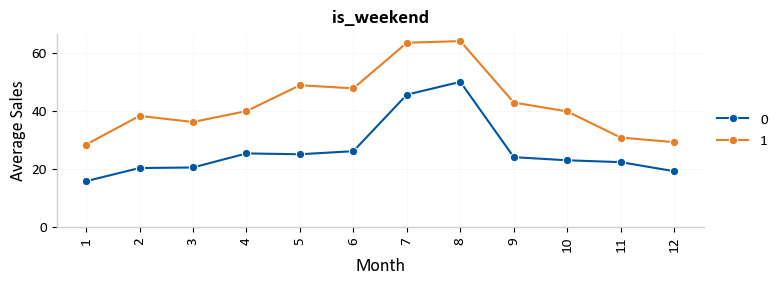

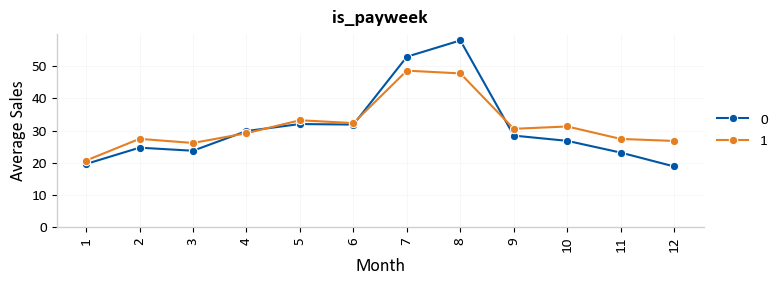

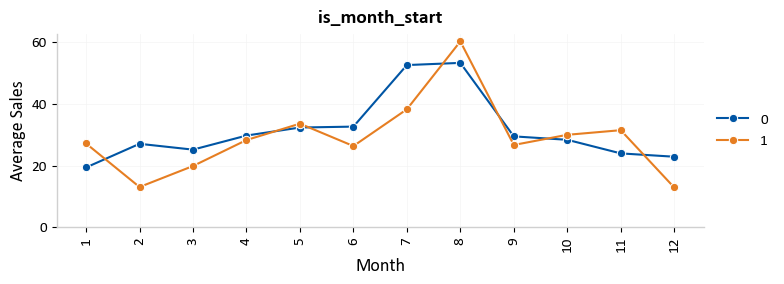

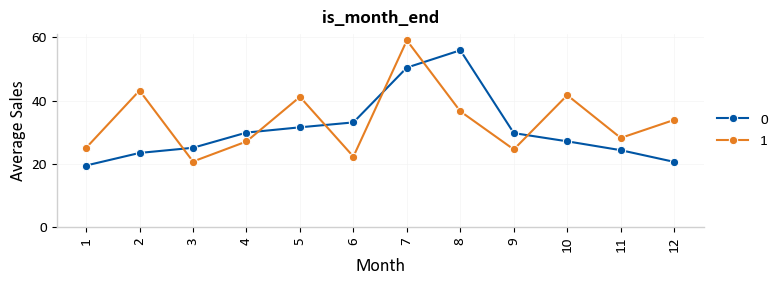

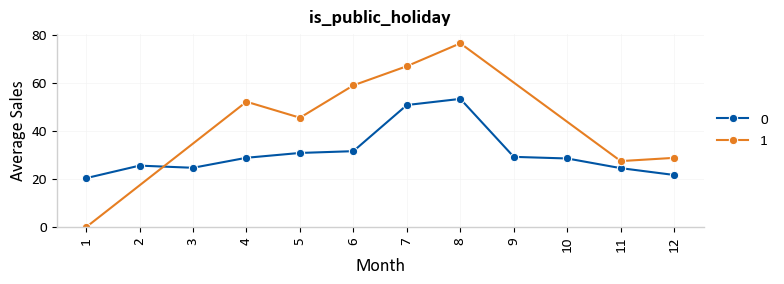

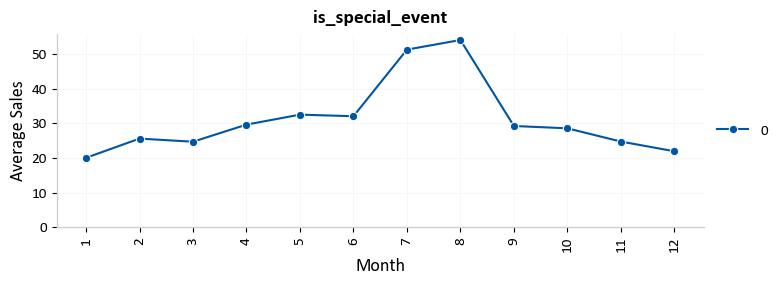

In [83]:
plot_categorical_predictors(data, cols_pred_cat_filtered)

## 5.2 Numerical

In [84]:
from scipy.stats import pearsonr

def check_numerical_predictors(
    data,
    cols_pred_num,
    target_col="y"
):
    results = []

    for pred in cols_pred_num:
        temp = data[[pred, target_col]].dropna()

        corr, p_val = pearsonr(
            temp[pred],
            temp[target_col]
        )

        results.append({
            "predictor": pred,
            "correlation": corr,
            "r2": corr ** 2,
            "p_value": p_val,
            "significance": "YES" if p_val < 0.05 else "NO"
        })

    return (
        pd.DataFrame(results)
        .sort_values("r2", ascending=False)
        .reset_index(drop=True)
        .style.map(
        color_red_green,
        subset=['significance']
        )
    )


In [85]:
check_numerical_predictors(
    data,
    cols_pred_num,
    target_col="y"
)

,predictor,correlation,r2,p_value,significance
0,lag_7,0.685196,0.469493,0.000000,YES
1,rolling_mean_7,0.613651,0.376567,0.000000,YES
2,lag_14,0.606661,0.368037,0.000000,YES
3,rolling_mean_14,0.599364,0.359237,0.000000,YES
4,lag_1,0.587371,0.345005,0.000000,YES
5,rolling_min_7,0.585346,0.342630,0.000000,YES
6,rolling_min_14,0.575626,0.331345,0.000000,YES
7,lag_21,0.543014,0.294864,0.000000,YES
8,rolling_max_7,0.537291,0.288681,0.000000,YES
9,rolling_min_28,0.530049,0.280952,0.000000,YES


In [86]:
from sklearn.metrics import r2_score

def plot_numerical_predictors(
    data,
    cols_pred_num,
    target_col="y"
):
    for pred in cols_pred_num:
        temp = data[[pred, target_col]].dropna()
        x_clean = temp[pred]
        y_clean = temp[target_col]

        # Calculate R² from simple linear regression
        slope, intercept = np.polyfit(x_clean, y_clean, 1)
        y_pred = slope * x_clean + intercept
        r2 = r2_score(y_clean, y_pred)
        
        fig, ax = plt.subplots(figsize=(6, 3))

        sns.regplot(
            data=data,
            x=pred,
            y=target_col,
            scatter_kws={"alpha": 0.5},
            line_kws={"color": "red"},
            ax=ax
        )

        # Add R² text
        plt.text(
            0.05, 0.95,              # Position (fraction of axes)
            f'R² = {r2:.3f}',         # Text to display
            transform=plt.gca().transAxes,  # Use axes coordinates
            fontsize=12,
            verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8),
            color='darkblue'
        )

        ax.set_title(f"{pred} vs {target_col}")
        plt.tight_layout()
        plt.show()


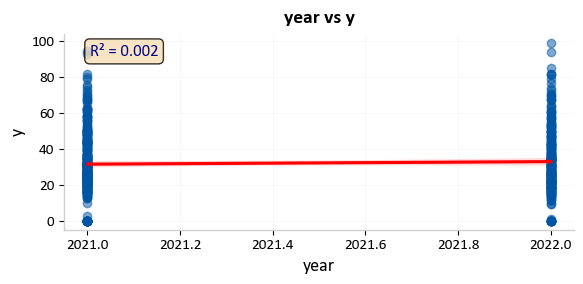

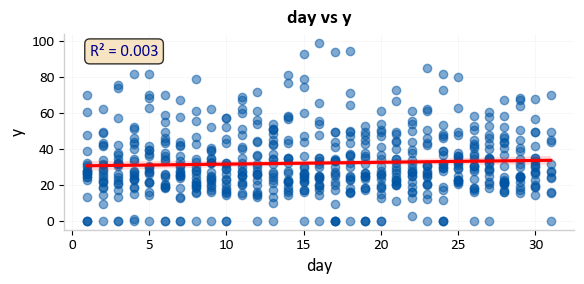

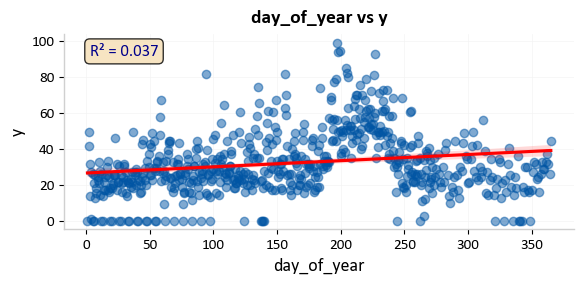

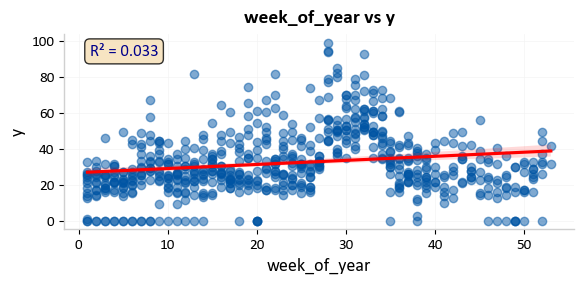

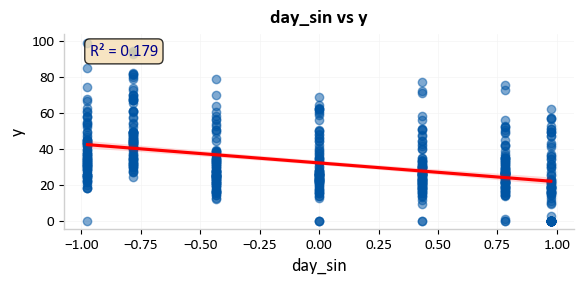

...

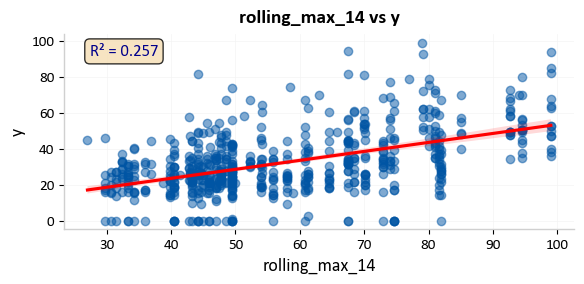

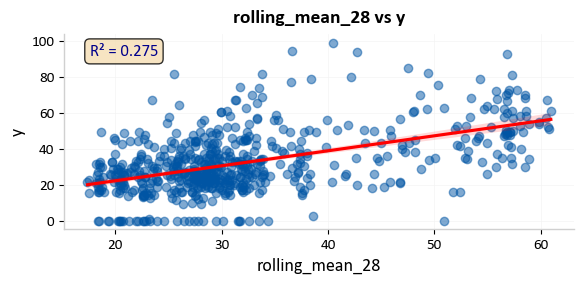

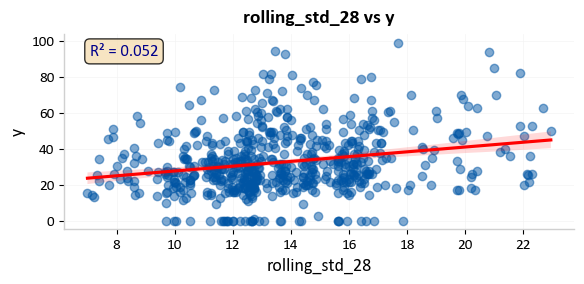

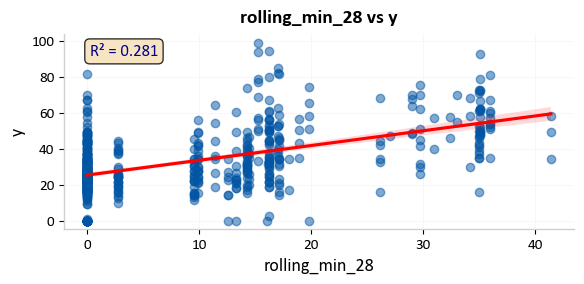

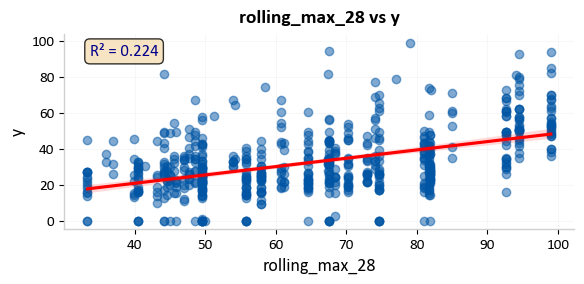

In [87]:
plot_numerical_predictors(data, cols_pred_num)

# 6. Statistical Forecasting

**Model**                      |	**Purpose**
- Naive                        |	Last observation
- Seasonal Naive               |	Previous seasonal observation
- Moving Average               | Historical window average
- Simple Exponential Smoothing |	Level
- Holt's Linear Trend          |	Level + trend
- Holt-Winters	               | Level + trend + seasonality
- ARIMA	                       | Autocorrelation and differencing
- SARIMA	                   | ARIMA with seasonality
- SARIMAX	                   | SARIMA with external variables

*Goal*: Compare all models against baseline forecasts. Understand why a more complex model doesn't necessarily perform better.

## 6.1 Baseline Model

In [88]:
# Naive forecast: Tomorrow's sales are predicted to equal today's sales.
def naive_forecast(train, horizon):
    last_value = train.iloc[-1]

    forecast = np.repeat(last_value, horizon)

    return pd.Series(
        forecast,
        index=pd.date_range(
            start=train.index[-1] + pd.Timedelta(days=1),
            periods=horizon,
            freq="D"
        ),
        name="naive"
    )

In [89]:
# Seasonal Naive forecast: Sales are predicted to equal sales from the same weekday in the previous week.
def seasonal_naive_forecast(train, horizon, seasonal_period=7):

    last_season = train.iloc[-seasonal_period:].values

    forecast = np.tile(
        last_season,
        int(np.ceil(horizon / seasonal_period))
    )[:horizon]

    return pd.Series(
        forecast,
        index=pd.date_range(
            start=train.index[-1] + pd.Timedelta(days=1),
            periods=horizon,
            freq="D"
        ),
        name="seasonal_naive"
    )

In [90]:
print("Train:", train.index.min(), train.index.max(), train.shape)
print("Test:", test.index.min(), test.index.max(), test.shape)

Train: 2021-01-02 00:00:00 2022-07-02 00:00:00 (547, 3)
Test: 2022-07-03 00:00:00 2022-09-30 00:00:00 (90, 3)


In [91]:
# forecast_horizon = len(test)

y_train = train["y"]
y_test = test["y"]

# Naive
pred_naive = naive_forecast(
    y_train,
    forecast_horizon
)

# Seasonal Naive
pred_seasonal_naive = seasonal_naive_forecast(
    y_train,
    forecast_horizon,
    seasonal_period=7
)

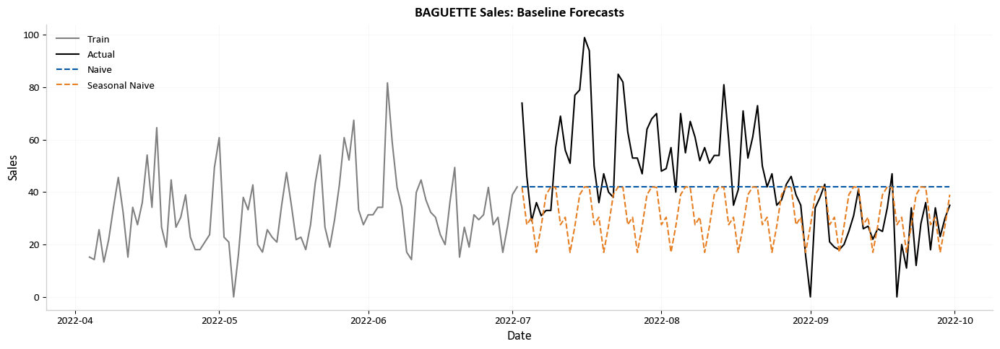

In [92]:
plt.figure(figsize=(14, 5))

plt.plot(y_train.tail(90), label="Train", color="gray")
plt.plot(y_test, label="Actual", color="black")

plt.plot(pred_naive, label="Naive", linestyle="--")
plt.plot(pred_seasonal_naive, label="Seasonal Naive", linestyle="--")

plt.title("BAGUETTE Sales: Baseline Forecasts")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.tight_layout()
plt.show()

In [93]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

def evaluate_forecast(actual, predicted, train, seasonal_period=7):

    actual = np.asarray(actual)
    predicted = np.asarray(predicted)
    train = np.asarray(train)

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    # MAPE: exclude zero actual values
    nonzero = actual != 0

    mape = (
        np.mean(np.abs(
            (actual[nonzero] - predicted[nonzero]) /
            actual[nonzero]
        )) * 100
        if nonzero.any() else np.nan
    )

    # MASE scaling denominator
    scale = np.mean(
        np.abs(train[seasonal_period:] - train[:-seasonal_period])
    )

    mase = mae / scale if scale != 0 else np.nan

    return {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape,
        "MASE": mase
    }

In [94]:
baseline_results = pd.DataFrame({
    "Naive": evaluate_forecast(y_test, pred_naive, y_train),
    "Seasonal Naive": evaluate_forecast(y_test, pred_seasonal_naive, y_train)
}).T

baseline_results

,MAE,RMSE,MAPE,MASE
Naive,16.111111,20.273683,41.794542,1.693909
Seasonal Naive,17.967222,22.831005,36.878920,1.889059


## 6.2 Exponential Smoothing

Exponential Smoothing is a family of statistical forecasting methods that predicts future values based on historical observations, giving more importance to recent observations than older ones.

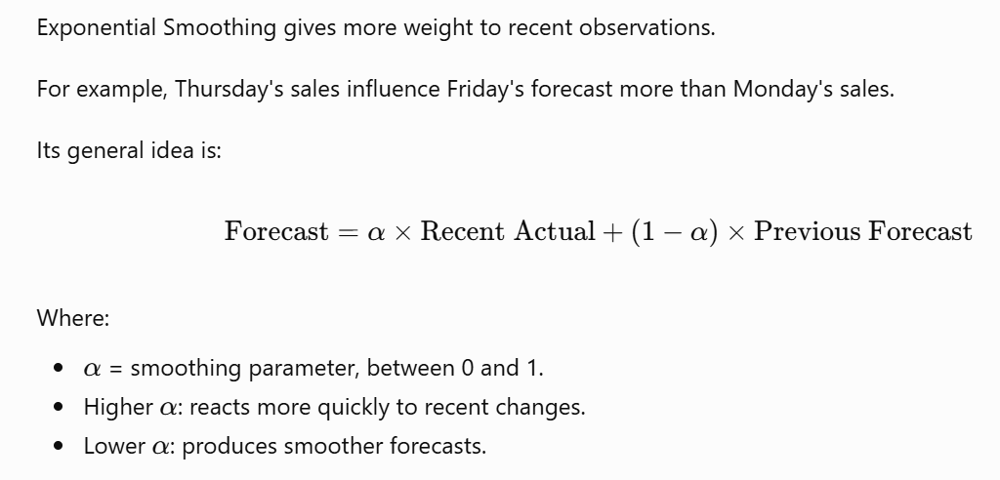

### 6.2.1 SES (Simple Exponential Smoothing)

In [96]:
from statsmodels.tsa.holtwinters import SimpleExpSmoothing

def fit_ses(train, horizon):

    model = SimpleExpSmoothing(
        train,
        initialization_method="estimated"
    )

    fitted_model = model.fit(optimized=True)
    forecast = fitted_model.forecast(horizon)

    return fitted_model, forecast

ImportError: DLL load failed while importing _initialization: An Application Control policy has blocked this file.

In [96]:
ses_model, pred_ses = fit_ses(
    y_train,
    horizon=len(y_test)
)

In [97]:
ses_model.params

{'smoothing_level': np.float64(0.12571561251761673),
 'smoothing_trend': np.float64(nan),
 'smoothing_seasonal': np.float64(nan),
 'damping_trend': nan,
 'initial_level': np.float64(24.598733796846275),
 'initial_trend': np.float64(nan),
 'initial_seasons': array([], dtype=float64),
 'use_boxcox': False,
 'lamda': None,
 'remove_bias': False}

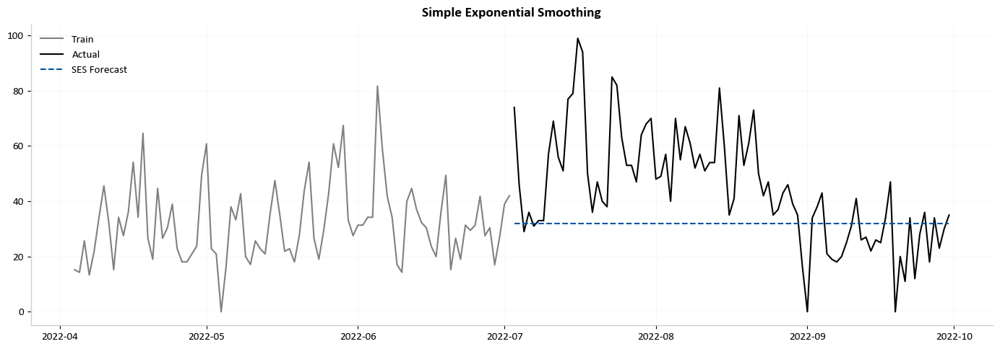

In [98]:
plt.figure(figsize=(14, 5))

plt.plot(y_train.index[-90:], y_train.tail(90),
         label="Train", color="gray")

plt.plot(y_test, label="Actual", color="black")

plt.plot(pred_ses, label="SES Forecast", linestyle="--")

plt.title("Simple Exponential Smoothing")
plt.legend()
plt.tight_layout()
plt.show()

In [99]:
evaluate_forecast(y_test, pred_ses, y_train)

{'MAE': 18.464974518531502,
 'RMSE': np.float64(23.84226020975481),
 'MAPE': np.float64(38.551541889374604),
 'MASE': np.float64(1.94139197243154)}

### 6.2.2 Holt's Linear Trend

In [100]:
from statsmodels.tsa.holtwinters import Holt

def fit_holt(train, horizon):

    model = Holt(
        train,
        initialization_method="estimated"
    )

    fitted_model = model.fit(optimized=True)

    forecast = fitted_model.forecast(horizon)

    return fitted_model, forecast

In [101]:
holt_model, pred_holt = fit_holt(
    y_train,
    horizon=len(y_test)
)

holt_model.params

{'smoothing_level': np.float64(0.12553165744097797),
 'smoothing_trend': np.float64(0.0),
 'smoothing_seasonal': np.float64(nan),
 'damping_trend': nan,
 'initial_level': np.float64(24.48513244659756),
 'initial_trend': np.float64(0.01358486428596925),
 'initial_seasons': array([], dtype=float64),
 'use_boxcox': False,
 'lamda': None,
 'remove_bias': False}

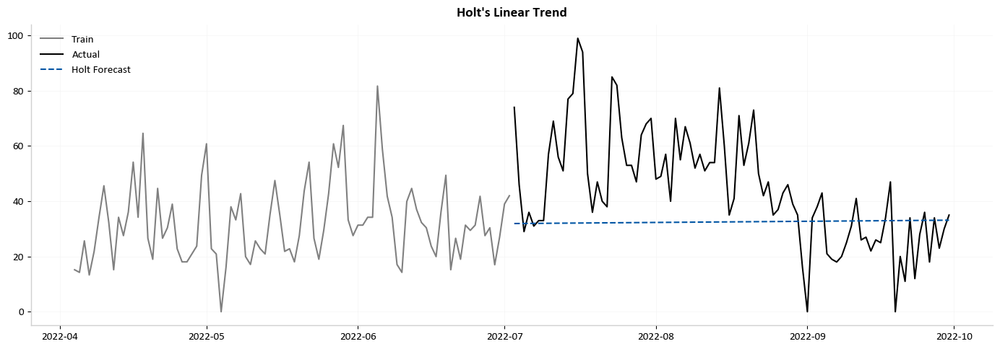

In [102]:
plt.figure(figsize=(14, 5))

plt.plot(y_train.index[-90:], y_train.tail(90), label="Train", color="gray")

plt.plot(y_test, label="Actual", color="black")
plt.plot(pred_holt, label="Holt Forecast", linestyle="--")

plt.title("Holt's Linear Trend")
plt.legend()
plt.tight_layout()
plt.show()

In [103]:
evaluate_forecast(
    y_test,
    pred_holt,
    y_train
)

{'MAE': 18.275895272101884,
 'RMSE': np.float64(23.650982999896524),
 'MAPE': np.float64(38.73735503345923),
 'MASE': np.float64(1.9215123386522752)}

### 6.2.3 Holt-Winters

In [104]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

def fit_holt_winters(
    train,
    horizon,
    seasonal_period=7,
    trend="add",
    seasonal="add"
):
    model = ExponentialSmoothing(
        train,
        trend=trend,
        seasonal=seasonal,
        seasonal_periods=seasonal_period,
        initialization_method="estimated"
    )

    fitted_model = model.fit(optimized=True)
    forecast = fitted_model.forecast(horizon)

    return fitted_model, forecast

In [105]:
hw_model, pred_hw = fit_holt_winters(
    y_train,
    horizon=len(y_test),
    seasonal_period=7
)

In [106]:
hw_model.params

{'smoothing_level': np.float64(0.2119247604656777),
 'smoothing_trend': np.float64(0.0),
 'smoothing_seasonal': np.float64(0.07361194039676497),
 'damping_trend': nan,
 'initial_level': np.float64(23.974974323292248),
 'initial_trend': np.float64(0.016689247471455206),
 'initial_seasons': array([  7.45101333,  16.61852329,   0.17569027,  -0.08709948,
        -19.54412145,  -2.31919801,  -0.46761745]),
 'use_boxcox': False,
 'lamda': None,
 'remove_bias': False}

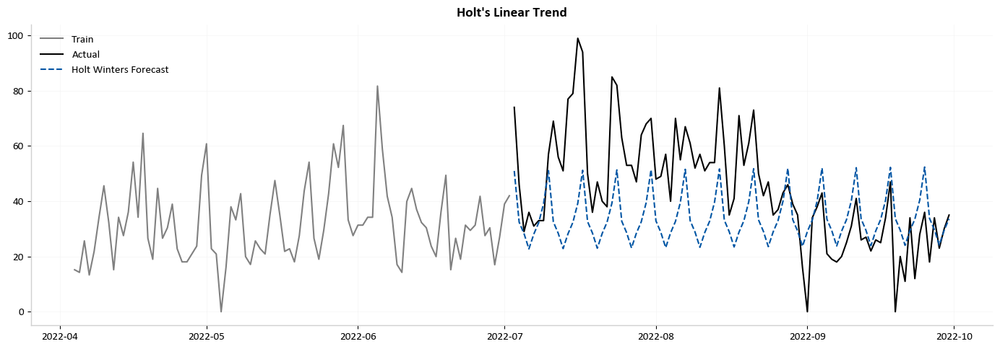

In [107]:
plt.figure(figsize=(14, 5))

plt.plot(y_train.index[-90:], y_train.tail(90), label="Train", color="gray")

plt.plot(y_test, label="Actual", color="black")
plt.plot(pred_hw, label="Holt Winters Forecast", linestyle="--")

plt.title("Holt's Linear Trend")
plt.legend()
plt.tight_layout()
plt.show()

In [108]:
evaluate_forecast(y_test, pred_hw, y_train)

{'MAE': 16.93440184399231,
 'RMSE': np.float64(21.29332965110972),
 'MAPE': np.float64(35.63190009777843),
 'MASE': np.float64(1.7804688419613997)}

In [109]:
(y_train == 0).sum()

np.int64(35)

In [110]:
y_train[y_train == 0]

ds
2021-01-06    0.0
2021-01-13    0.0
2021-01-20    0.0
2021-01-27    0.0
2021-02-03    0.0
2021-02-10    0.0
2021-02-17    0.0
2021-02-24    0.0
2021-03-03    0.0
2021-03-10    0.0
2021-03-17    0.0
2021-03-24    0.0
2021-03-31    0.0
2021-04-07    0.0
2021-05-17    0.0
2021-05-18    0.0
2021-05-19    0.0
2021-05-20    0.0
2021-11-17    0.0
2021-11-24    0.0
2021-12-01    0.0
2021-12-06    0.0
2021-12-07    0.0
2021-12-08    0.0
2021-12-15    0.0
2022-01-01    0.0
2022-01-05    0.0
2022-01-12    0.0
2022-01-19    0.0
2022-01-26    0.0
2022-02-02    0.0
2022-02-09    0.0
2022-02-16    0.0
2022-02-23    0.0
2022-05-04    0.0
Name: y, dtype: float64

In [111]:
# hw_add_model, pred_hw_add = fit_holt_winters(
#     y_train,
#     horizon=len(y_test),
#     seasonal_period=7,
#     trend="add",
#     seasonal="add"
# )

# hw_mul_model, pred_hw_mul = fit_holt_winters(
#     y_train,
#     horizon=len(y_test),
#     seasonal_period=7,
#     trend="add",
#     seasonal="mul"
# )

## 6.3 ARIMA / SARIMA / SARIMAX

In [97]:
from statsmodels.graphics.tsaplots import plot_acf
import matplotlib.pyplot as plt

def plot_residual_diagnostics(
    model,
    lags=35,
    figsize=(14, 7),
    title="SARIMA"
):
    residuals = model.resid

    fig, axes = plt.subplots(2, 1, figsize=figsize)

    # Residual time series
    axes[0].plot(residuals)
    axes[0].axhline(0, color="red", linestyle="--")
    axes[0].set_title(f"{title} Residuals")

    # Residual ACF
    plot_acf(residuals, lags=lags, ax=axes[1])
    axes[1].set_title("Residual ACF")

    plt.tight_layout()
    plt.show()

In [98]:
from statsmodels.stats.diagnostic import acorr_ljungbox

def check_residual_autocorrelation(
    model,
    order,
    seasonal_order,
    lags=[7, 14, 21, 28]
):
    p, d, q = order
    P, D, Q, s = seasonal_order

    model_df = p + q + P + Q

    result = acorr_ljungbox(
        model.resid,
        lags=lags,
        model_df=model_df,
        return_df=True
    )

    result["conclusion"] = result["lb_pvalue"].apply(
        lambda x: "Significant autocorrelation"
        if x < 0.05
        else "No significant autocorrelation detected"
    )

    return result

In [99]:
def evaluate_residuals(
    model,
    order,
    seasonal_order,
    title="SARIMA",
    lags=35,
    lb_lags=[7, 14, 21, 28]
):
    plot_residual_diagnostics(
        model=model,
        lags=lags,
        title=title
    )

    result = check_residual_autocorrelation(
        model=model,
        order=order,
        seasonal_order=seasonal_order,
        lags=lb_lags
    )

    return result

### 6.3.1 Time-Series Characteristics

#### 6.3.1.1 Stationarity Analysis

In [100]:
perform_adf_test(y_train)

p-value: 0.0977829808761218
The data is not stationary, Data can be processed further


In [101]:
# First-order differencing
train_diff = y_train.diff().dropna()

# Seasonal differencing (weekly)
train_seasonal_diff = y_train.diff(7).dropna()

# Both first-order and seasonal differencing
train_both_diff = y_train.diff(7).diff().dropna()

perform_adf_test(train_diff)
perform_adf_test(train_seasonal_diff)
perform_adf_test(train_both_diff)

p-value: 3.234094601629866e-12
The data is stationary
p-value: 1.9210812767890432e-07
The data is stationary
p-value: 7.847181255282685e-11
The data is stationary


#### 6.3.1.2 ACF/PACF Analysis

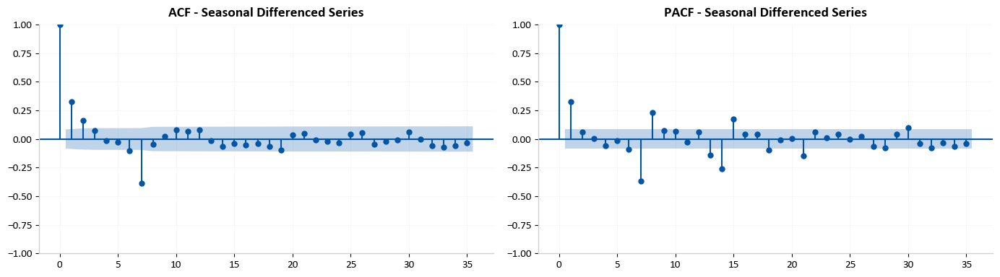

In [102]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import matplotlib.pyplot as plt

train_seasonal_diff = y_train.diff(7).dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

plot_acf(train_seasonal_diff, lags=35, ax=axes[0])
axes[0].set_title("ACF - Seasonal Differenced Series")

plot_pacf(train_seasonal_diff, lags=35, ax=axes[1], method="ywm")
axes[1].set_title("PACF - Seasonal Differenced Series")

plt.tight_layout()
plt.show()

Component	Observation	Candidate
- Non-seasonal AR (p):	Positive spike at lag 1 in PACF	p=1
- Non-seasonal MA (q):	Positive spike at lag 1 in ACF	q=1
- Seasonal AR (P):	Significant spike at lag 7 in PACF	P=1
- Seasonal MA (Q):	Strong spike at lag 7 in ACF	Q=1

### 6.3.2 Manual ARIMA / SARIMA [EXP]

#### 6.3.2.1 Model Candidates

- Method: Fit all candidates on full y_train; compare AIC/BIC
- Purpose: Initial model screening

In [103]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

def fit_sarima(
    train,
    order,
    seasonal_order
):
    model = SARIMAX(
        train,
        order=order,
        seasonal_order=seasonal_order,
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    fitted_model = model.fit(disp=False)

    return fitted_model

In [104]:
candidates = {
    "SARIMA_A": ((1, 0, 1), (1, 0, 1, 7)),
    "SARIMA_B": ((1, 0, 1), (0, 1, 1, 7)),
    "SARIMA_C": ((1, 0, 0), (0, 1, 1, 7)),
    "SARIMA_D": ((0, 0, 1), (0, 1, 1, 7)),
    "SARIMA_E": ((1, 1, 1), (0, 1, 1, 7))
}

In [105]:
models = {}
results = []

for name, (order, seasonal_order) in tqdm(
    candidates.items(),
    total=len(candidates),
    desc="Fitting SARIMA models"
):
    fitted_model = fit_sarima(
        y_train,
        order,
        seasonal_order
    )

    models[name] = fitted_model

    results.append({
        "model": name,
        "order": order,
        "seasonal_order": seasonal_order,
        "AIC": fitted_model.aic,
        "BIC": fitted_model.bic
    })

sarima_results = (
    pd.DataFrame(results)
    .sort_values("AIC")
    .reset_index(drop=True)
)

sarima_results

Fitting SARIMA models: 100%|█████████████████████████████████████████████████████████████| 5/5 [00:01<00:00,  3.76it/s]


,model,order,seasonal_order,AIC,BIC
0,SARIMA_E,"(1, 1, 1)","(0, 1, 1, 7)",3963.438750,3980.530258
1,SARIMA_B,"(1, 0, 1)","(0, 1, 1, 7)",3970.862168,3987.961216
2,SARIMA_C,"(1, 0, 0)","(0, 1, 1, 7)",4003.014174,4015.844105
3,SARIMA_A,"(1, 0, 1)","(1, 0, 1, 7)",4019.464706,4040.903999
4,SARIMA_D,"(0, 0, 1)","(0, 1, 1, 7)",4032.622392,4045.446678


#### 6.3.2.2 Residual Diagnostics

In [106]:
# # define best model
# name = "SARIMA_E"
# order, seasonal_order = candidates[name]

# residual_results = {}

# result = evaluate_residuals(
#     model=models[name],
#     order=order,
#     seasonal_order=seasonal_order,
#     title=name
# )

# residual_results[name] = result

# display(result)

Residual Diagnostics:   0%|                                                                      | 0/5 [00:00<?, ?it/s]


SARIMA_A


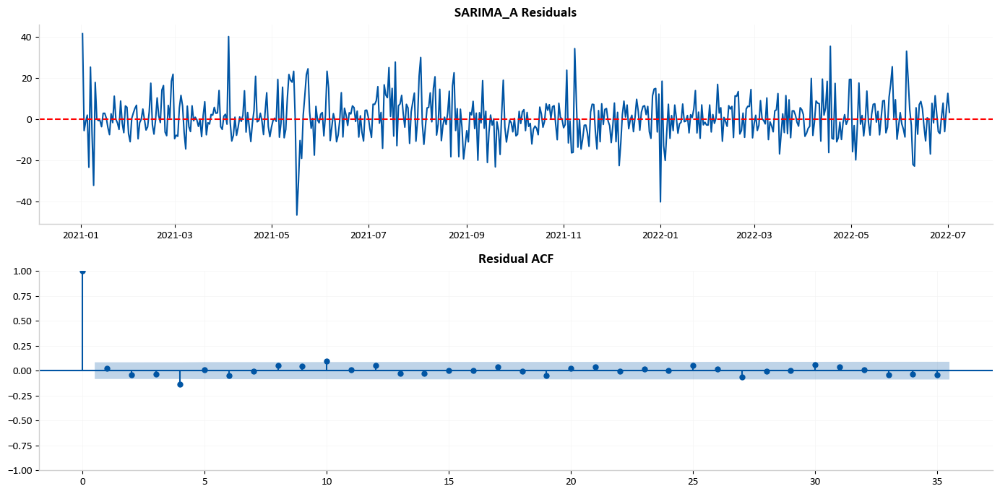

,lb_stat,lb_pvalue,conclusion
7,13.424530,0.003803,Significant autocorrelation
14,23.686734,0.008477,Significant autocorrelation
21,26.868971,0.060018,No significant autocorrelation detected
28,31.412098,0.142253,No significant autocorrelation detected


Residual Diagnostics:  20%|████████████▍                                                 | 1/5 [00:00<00:01,  2.62it/s]


SARIMA_B


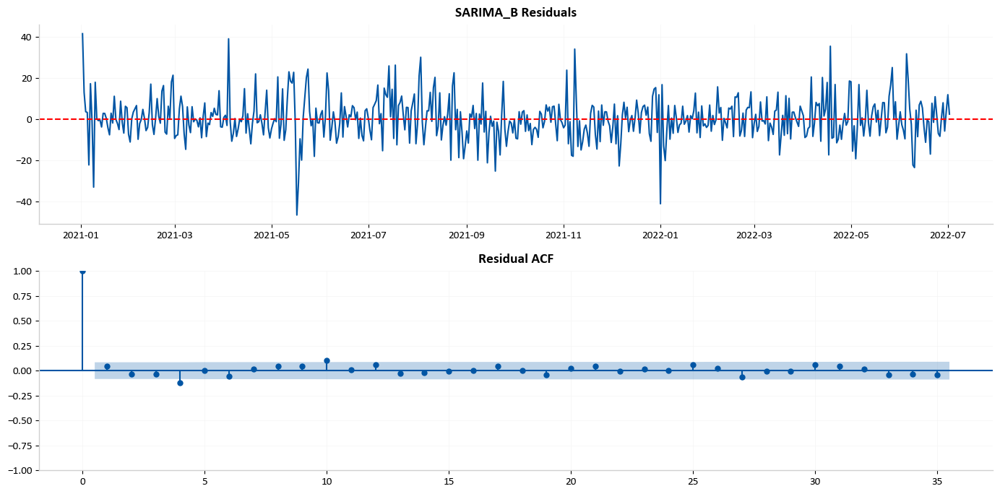

,lb_stat,lb_pvalue,conclusion
7,12.775709,0.012425,Significant autocorrelation
14,23.443232,0.015296,Significant autocorrelation
21,26.791101,0.082998,No significant autocorrelation detected
28,31.720762,0.166251,No significant autocorrelation detected


Residual Diagnostics:  40%|████████████████████████▊                                     | 2/5 [00:00<00:00,  3.38it/s]


SARIMA_C


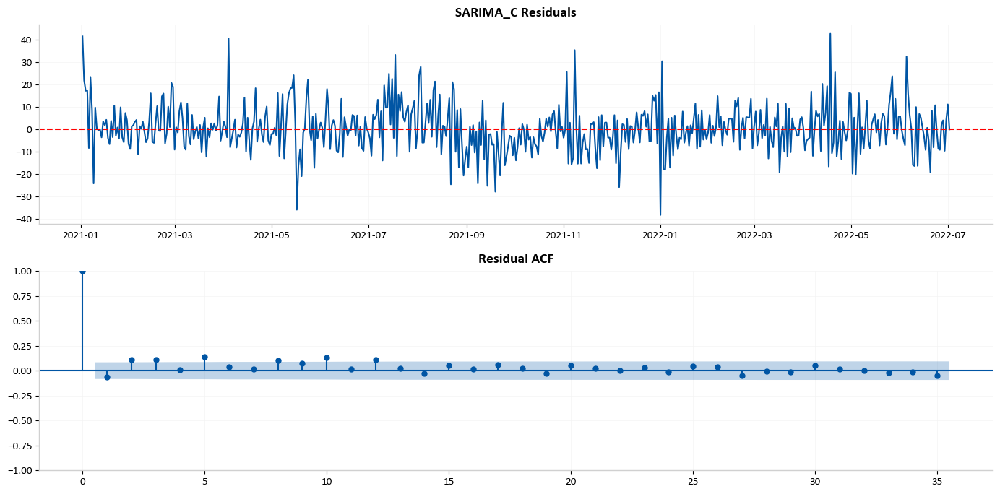

,lb_stat,lb_pvalue,conclusion
7,27.617449,4.323291e-05,Significant autocorrelation
14,53.604418,3.214983e-07,Significant autocorrelation
21,59.537618,4.578572e-06,Significant autocorrelation
28,63.694095,5.241641e-05,Significant autocorrelation


Residual Diagnostics:  60%|█████████████████████████████████████▏                        | 3/5 [00:00<00:00,  3.22it/s]


SARIMA_D


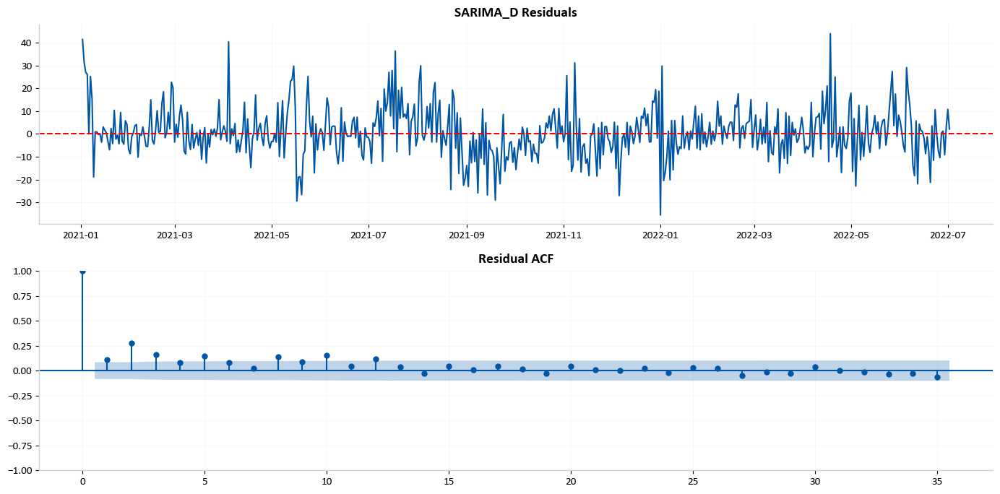

,lb_stat,lb_pvalue,conclusion
7,83.169732,1.820782e-16,Significant autocorrelation
14,121.866118,2.622459e-20,Significant autocorrelation
21,126.120823,7.874465e-18,Significant autocorrelation
28,128.927525,1.326916e-15,Significant autocorrelation


Residual Diagnostics:  80%|█████████████████████████████████████████████████▌            | 4/5 [00:01<00:00,  3.21it/s]


SARIMA_E


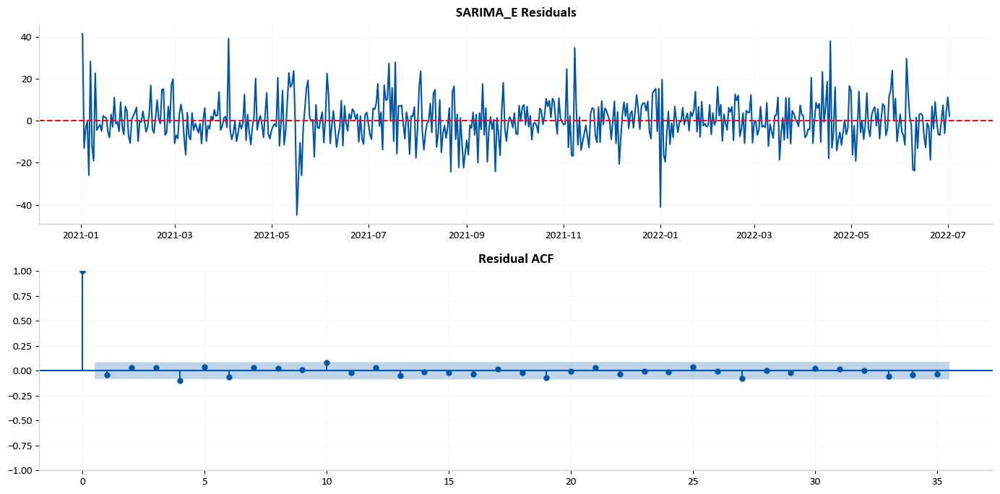

,lb_stat,lb_pvalue,conclusion
7,11.149850,0.024931,Significant autocorrelation
14,17.162102,0.103171,No significant autocorrelation detected
21,21.932975,0.234974,No significant autocorrelation detected
28,27.505322,0.331122,No significant autocorrelation detected


Residual Diagnostics: 100%|██████████████████████████████████████████████████████████████| 5/5 [00:01<00:00,  3.28it/s]


In [107]:
residual_results = {}

for name, (order, seasonal_order) in tqdm(
    candidates.items(),
    total=len(candidates),
    desc="Residual Diagnostics"
):
    print(f"\n{'='*50}")
    print(name)
    print(f"{'='*50}")

    result = evaluate_residuals(
        model=models[name],
        order=order,
        seasonal_order=seasonal_order,
        title=name
    )

    residual_results[name] = result

    display(result)

In [108]:
best_model = models["SARIMA_E"]

pred_sarima = best_model.forecast(steps=len(y_test))

pred_sarima.index = y_test.index
pred_sarima.name = "SARIMA"

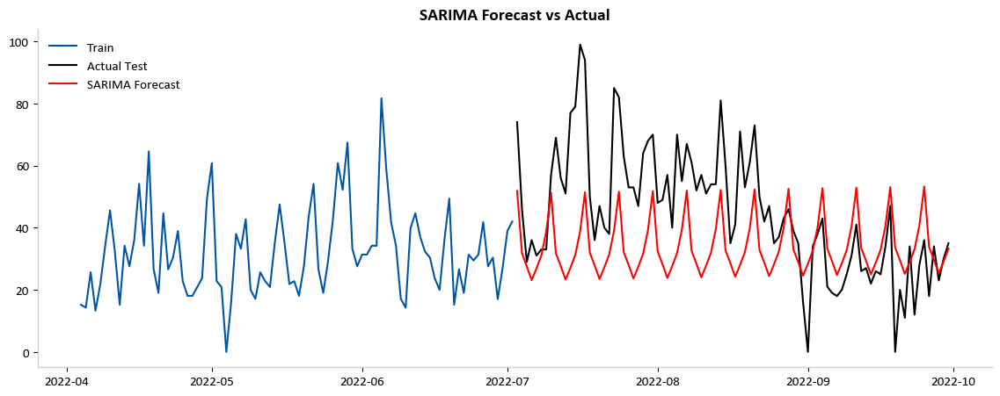

In [109]:
plt.figure(figsize=(14, 5))

plt.plot(y_train.index[-90:], y_train.tail(90), label="Train")
plt.plot(y_test.index, y_test, label="Actual Test", color="black")
plt.plot(pred_sarima.index, pred_sarima, label="SARIMA Forecast", color="red")

plt.title("SARIMA Forecast vs Actual")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [110]:
sarima_metrics = evaluate_forecast(
    actual=y_test,
    predicted=pred_sarima,
    train=y_train,
    seasonal_period=7
)

sarima_metrics

{'MAE': 17.210532208289663,
 'RMSE': np.float64(21.489492225049894),
 'MAPE': np.float64(36.43245476259074),
 'MASE': np.float64(1.8095009574432528)}

#### 6.3.2.3 Time Series Cross-Validation

In [111]:
from sklearn.model_selection import TimeSeriesSplit
from tqdm.auto import tqdm

tscv = TimeSeriesSplit(
    n_splits=3,
    test_size=forecast_horizon
)

cv_results = []

for name, (order, seasonal_order) in tqdm(
    candidates.items(),
    total=len(candidates),
    desc="SARIMA Cross-Validation"
):

    for fold, (train_idx, valid_idx) in enumerate(
        tscv.split(y_train), start=1
    ):

        cv_train = y_train.iloc[train_idx]
        cv_valid = y_train.iloc[valid_idx]

        fitted_model = fit_sarima(
            cv_train,
            order,
            seasonal_order
        )

        forecast = fitted_model.forecast(
            steps=len(cv_valid)
        )

        metrics = evaluate_forecast(
            actual=cv_valid,
            predicted=forecast,
            train=cv_train,
            seasonal_period=7
        )

        cv_results.append({
            "model": name,
            "fold": fold,
            "order": order,
            "seasonal_order": seasonal_order,
            **metrics
        })

cv_results = pd.DataFrame(cv_results)

SARIMA Cross-Validation:   0%|          | 0/5 [00:00<?, ?it/s]

In [112]:
cv_results.sort_values(["model", "fold"])

,model,fold,order,seasonal_order,MAE,RMSE,MAPE,MASE
0,SARIMA_A,1,"(1, 0, 1)","(1, 0, 1, 7)",7.685857,10.199391,27.444239,0.785072
1,SARIMA_A,2,"(1, 0, 1)","(1, 0, 1, 7)",7.512559,9.237778,53.591771,0.773096
2,SARIMA_A,3,"(1, 0, 1)","(1, 0, 1, 7)",13.428259,17.135497,37.362932,1.476697
3,SARIMA_B,1,"(1, 0, 1)","(0, 1, 1, 7)",10.657073,13.229444,42.120266,1.088567
4,SARIMA_B,2,"(1, 0, 1)","(0, 1, 1, 7)",6.358912,7.971556,51.157059,0.654377
5,SARIMA_B,3,"(1, 0, 1)","(0, 1, 1, 7)",11.157561,14.743490,31.789796,1.226989
6,SARIMA_C,1,"(1, 0, 0)","(0, 1, 1, 7)",10.101391,12.597987,39.536557,1.031807
7,SARIMA_C,2,"(1, 0, 0)","(0, 1, 1, 7)",6.930047,8.699684,51.290240,0.713151
8,SARIMA_C,3,"(1, 0, 0)","(0, 1, 1, 7)",10.788560,14.335212,30.312412,1.186411
9,SARIMA_D,1,"(0, 0, 1)","(0, 1, 1, 7)",8.834238,11.370596,33.353599,0.902374


In [113]:
cv_summary = (
    cv_results
    .groupby("model")
    .agg({
        "MAE": "mean",
        "RMSE": "mean",
        "MAPE": "mean",
        "MASE": "mean"
    })
    .sort_values("MAE")
    .reset_index()
)

cv_summary

,model,MAE,RMSE,MAPE,MASE
0,SARIMA_D,9.190989,11.894729,39.217874,0.969036
1,SARIMA_C,9.273332,11.877628,40.379736,0.977123
2,SARIMA_B,9.391182,11.981497,41.689040,0.989978
3,SARIMA_A,9.542225,12.190889,39.466314,1.011622
4,SARIMA_E,13.877015,16.978532,59.587467,1.454496


#### 6.3.2.4 Model Selection

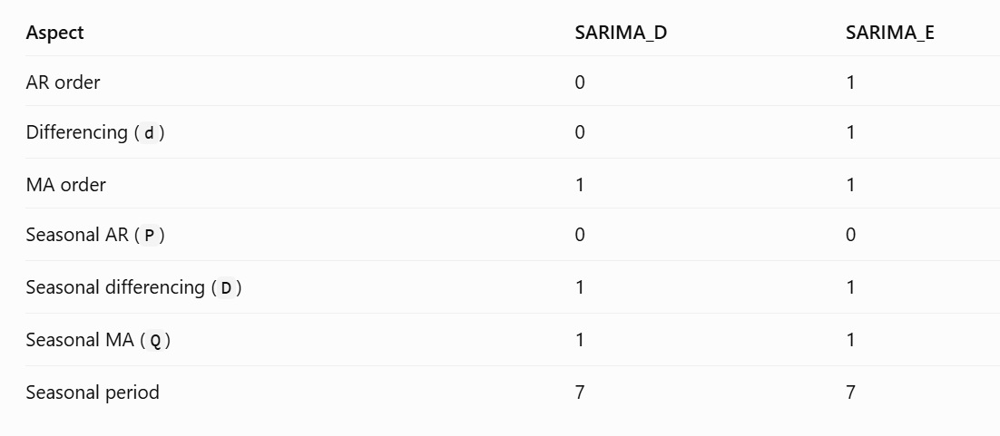

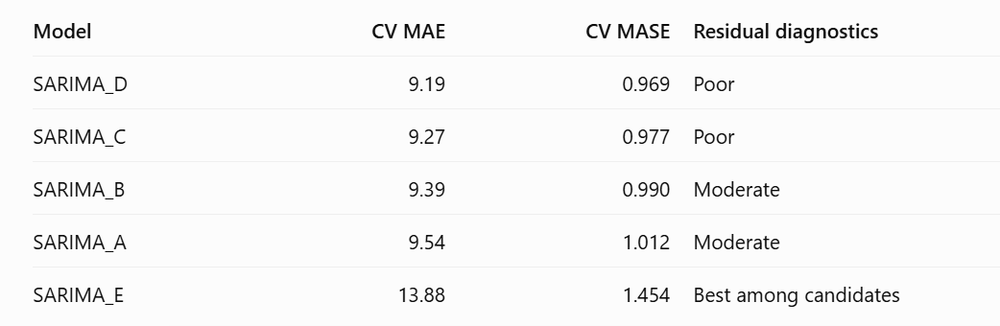

In [114]:
# Baseline model CV
from sklearn.model_selection import TimeSeriesSplit
from tqdm.auto import tqdm

tscv = TimeSeriesSplit(
    n_splits=3,
    test_size=forecast_horizon
)

cv_baseline_results = []

for fold, (train_idx, valid_idx) in enumerate(
    tscv.split(y_train), start=1
):
    cv_train = y_train.iloc[train_idx]
    cv_valid = y_train.iloc[valid_idx]

    # Naive forecast
    naive_forecast_values = naive_forecast(
        cv_train,
        horizon=len(cv_valid)
    )

    naive_metrics = evaluate_forecast(
        actual=cv_valid,
        predicted=naive_forecast_values,
        train=cv_train,
        seasonal_period=7
    )

    cv_baseline_results.append({
        "model": "Naive",
        "fold": fold,
        **naive_metrics
    })

    # Seasonal Naive forecast
    seasonal_forecast_values = seasonal_naive_forecast(
        cv_train,
        horizon=len(cv_valid),
        seasonal_period=7
    )

    seasonal_metrics = evaluate_forecast(
        actual=cv_valid,
        predicted=seasonal_forecast_values,
        train=cv_train,
        seasonal_period=7
    )

    cv_baseline_results.append({
        "model": "Seasonal Naive",
        "fold": fold,
        **seasonal_metrics
    })

cv_baseline_results = pd.DataFrame(cv_baseline_results)

In [115]:
cv_baseline_summary = (
    cv_baseline_results
    .groupby("model")
    .agg({
        "MAE": "mean",
        "RMSE": "mean",
        "MAPE": "mean",
        "MASE": "mean"
    })
    .sort_values("MAE")
    .reset_index()
)

cv_baseline_summary

,model,MAE,RMSE,MAPE,MASE
0,Naive,10.878519,13.806965,41.490116,1.141856
1,Seasonal Naive,12.190185,15.146988,59.076984,1.280681


In [116]:
cv_comparison = pd.concat(
    [
        cv_baseline_summary,
        cv_summary
    ],
    ignore_index=True
).sort_values("MAE").reset_index(drop=True)

cv_comparison

,model,MAE,RMSE,MAPE,MASE
0,SARIMA_D,9.190989,11.894729,39.217874,0.969036
1,SARIMA_C,9.273332,11.877628,40.379736,0.977123
2,SARIMA_B,9.391182,11.981497,41.689040,0.989978
3,SARIMA_A,9.542225,12.190889,39.466314,1.011622
4,Naive,10.878519,13.806965,41.490116,1.141856
5,Seasonal Naive,12.190185,15.146988,59.076984,1.280681
6,SARIMA_E,13.877015,16.978532,59.587467,1.454496


In [117]:
residual_summary = []

for name, result in residual_results.items():
    residual_summary.append({
        "model": name,
        "significant_lags": (result["lb_pvalue"] < 0.05).sum(),
        "total_lags": len(result)
    })

residual_summary = pd.DataFrame(residual_summary)

model_selection = (
    cv_comparison
    .merge(residual_summary, on="model", how="left")
    .sort_values("MAE")
    .reset_index(drop=True)
)

model_selection

,model,MAE,RMSE,MAPE,MASE,significant_lags,total_lags
0,SARIMA_D,9.190989,11.894729,39.217874,0.969036,4.0,4.0
1,SARIMA_C,9.273332,11.877628,40.379736,0.977123,4.0,4.0
2,SARIMA_B,9.391182,11.981497,41.689040,0.989978,2.0,4.0
3,SARIMA_A,9.542225,12.190889,39.466314,1.011622,2.0,4.0
4,Naive,10.878519,13.806965,41.490116,1.141856,NaN,NaN
5,Seasonal Naive,12.190185,15.146988,59.076984,1.280681,NaN,NaN
6,SARIMA_E,13.877015,16.978532,59.587467,1.454496,1.0,4.0


#### 6.3.2.5 Model Evaluation

In [118]:
best_model_name = "SARIMA_B"

best_order, best_seasonal_order = candidates[best_model_name]

final_model = fit_sarima(
    y_train,
    best_order,
    best_seasonal_order
)

final_forecast = final_model.forecast(
    steps=len(y_test)
)

final_metrics = evaluate_forecast(
    actual=y_test,
    predicted=final_forecast,
    train=y_train,
    seasonal_period=7
)

pd.DataFrame([final_metrics], index=[best_model_name])

,MAE,RMSE,MAPE,MASE
SARIMA_B,17.078189,21.557907,35.110734,1.795586


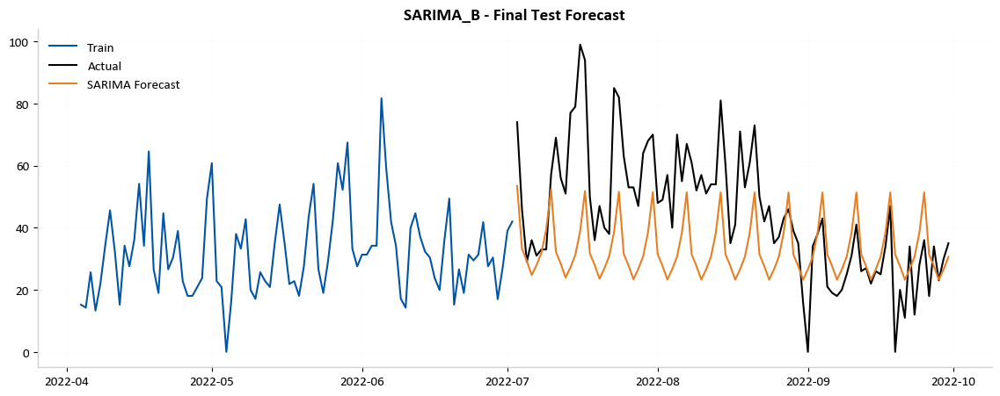

In [119]:
plt.figure(figsize=(14, 5))

plt.plot(y_train.tail(90), label="Train")
plt.plot(y_test, label="Actual", color="black")
plt.plot(final_forecast, label="SARIMA Forecast")

plt.title(f"{best_model_name} - Final Test Forecast")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 6.3.3. Auto ARIMA [EXP]

The purpose of Auto ARIMA is to automate the selection of ARIMA/SARIMA orders rather than manually defining candidate combinations.

#### 6.3.3.1 Automated Model Selection

In [121]:
# from pmdarima import auto_arima

# auto_model = auto_arima(
#     y_train,

#     # Non-seasonal parameters
#     start_p=0,
#     start_q=0,
#     max_p=3,
#     max_q=3,
#     d=None,

#     # Seasonal parameters
#     seasonal=True,
#     m=7,  # weekly seasonality
#     start_P=0,
#     start_Q=0,
#     max_P=2,
#     max_Q=2,
#     D=None,

#     # Model selection
#     information_criterion="aic",
#     stepwise=True,

#     # Other settings
#     trace=True,
#     error_action="ignore",
#     suppress_warnings=True,
#     n_jobs=1
# )

In [122]:
# print(auto_model.summary())

In [123]:
# auto_order = auto_model.order
# auto_seasonal_order = auto_model.seasonal_order

# print("ARIMA Order:", auto_order)
# print("Seasonal Order:", auto_seasonal_order)

In [124]:
from itertools import product
from statsmodels.tsa.statespace.sarimax import SARIMAX
from tqdm.auto import tqdm
import warnings

warnings.filterwarnings("ignore")

p_values = [0, 1, 2]
d_values = [0, 1]
q_values = [0, 1, 2]

P_values = [0, 1]
D_values = [0, 1]
Q_values = [0, 1]

s = 7

candidates_auto = list(product(
    p_values,
    d_values,
    q_values,
    P_values,
    D_values,
    Q_values
))

len(candidates_auto)

144

In [125]:
auto_results = []

for p, d, q, P, D, Q in tqdm(
    candidates_auto,
    desc="Auto SARIMA"
):
    order = (p, d, q)
    seasonal_order = (P, D, Q, s)

    try:
        model = SARIMAX(
            y_train,
            order=order,
            seasonal_order=seasonal_order,
            enforce_stationarity=False,
            enforce_invertibility=False
        )

        fitted_model = model.fit(disp=False)

        auto_results.append({
            "order": order,
            "seasonal_order": seasonal_order,
            "AIC": fitted_model.aic,
            "BIC": fitted_model.bic
        })

    except Exception:
        continue

auto_results = pd.DataFrame(auto_results)

Auto SARIMA:   0%|          | 0/144 [00:00<?, ?it/s]

In [126]:
auto_results = (
    auto_results
    .sort_values("AIC")
    .reset_index(drop=True)
)

auto_results.head(10)

,order,seasonal_order,AIC,BIC
0,"(1, 1, 2)","(1, 1, 1, 7)",3956.944237,3982.570168
1,"(1, 1, 2)","(0, 1, 1, 7)",3957.327196,3978.682139
2,"(1, 0, 2)","(0, 1, 1, 7)",3958.073989,3979.438374
3,"(0, 1, 2)","(0, 1, 1, 7)",3958.092338,3975.176292
4,"(2, 0, 2)","(0, 1, 1, 7)",3958.286823,3983.924085
5,"(0, 1, 2)","(1, 1, 1, 7)",3958.312429,3979.667371
6,"(2, 1, 2)","(0, 1, 1, 7)",3958.674521,3984.300451
7,"(2, 1, 2)","(1, 1, 1, 7)",3958.915806,3988.812725
8,"(2, 0, 2)","(1, 1, 1, 7)",3959.352659,3989.262798
9,"(1, 0, 2)","(1, 1, 1, 7)",3959.899194,3985.536456


In [127]:
best_auto = auto_results.iloc[0]

auto_order = best_auto["order"]
auto_seasonal_order = best_auto["seasonal_order"]

auto_final_model = fit_sarima(
    y_train,
    auto_order,
    auto_seasonal_order
)

print("Best ARIMA order:", auto_order)
print("Best seasonal order:", auto_seasonal_order)
print("AIC:", auto_final_model.aic)
print("BIC:", auto_final_model.bic)

Best ARIMA order: (1, 1, 2)
Best seasonal order: (1, 1, 1, 7)
AIC: 3956.9442372477383
BIC: 3982.570167838888


#### 6.3.3.2 Residual Diagnostics

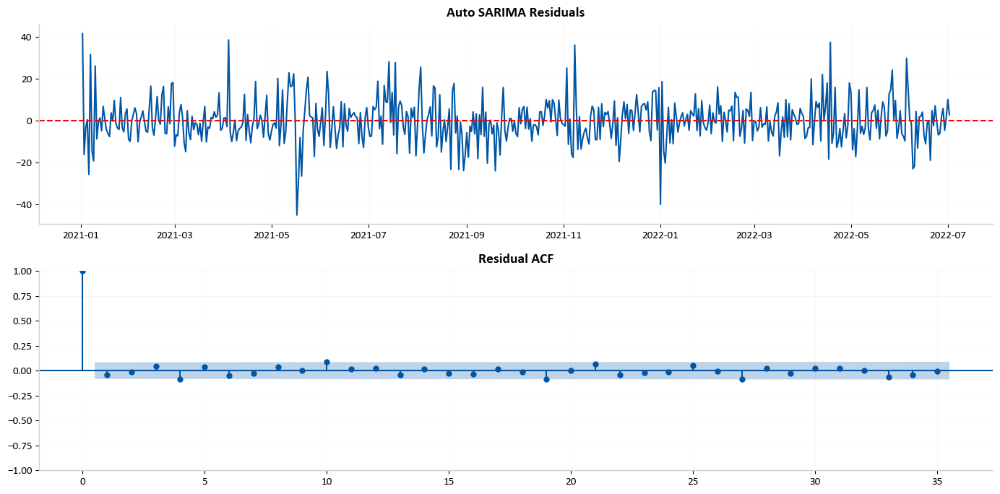

,lb_stat,lb_pvalue,conclusion
7,8.648083,0.013246,Significant autocorrelation
14,15.037938,0.089899,No significant autocorrelation detected
21,22.643537,0.123601,No significant autocorrelation detected
28,29.884643,0.152742,No significant autocorrelation detected


In [128]:
auto_residual_results = evaluate_residuals(
    model=auto_final_model,
    order=auto_order,
    seasonal_order=auto_seasonal_order,
    title="Auto SARIMA"
)

display(auto_residual_results)

#### 6.3.3.3 Time-Series Cross Validation

In [129]:
tscv = TimeSeriesSplit(
    n_splits=3,
    test_size=forecast_horizon
)

auto_cv_results = []

for fold, (train_idx, valid_idx) in enumerate(
    tscv.split(y_train), start=1
):

    cv_train = y_train.iloc[train_idx]
    cv_valid = y_train.iloc[valid_idx]

    fitted_model = fit_sarima(
        cv_train,
        auto_order,
        auto_seasonal_order
    )

    forecast = fitted_model.forecast(
        steps=len(cv_valid)
    )

    metrics = evaluate_forecast(
        actual=cv_valid,
        predicted=forecast,
        train=cv_train,
        seasonal_period=7
    )

    auto_cv_results.append({
        "model": "Auto SARIMA",
        "fold": fold,
        "order": auto_order,
        "seasonal_order": auto_seasonal_order,
        **metrics
    })

auto_cv_results = pd.DataFrame(auto_cv_results)

In [130]:
auto_cv_results

,model,fold,order,seasonal_order,MAE,RMSE,MAPE,MASE
0,Auto SARIMA,1,"(1, 1, 2)","(1, 1, 1, 7)",21.204269,25.198658,85.649177,2.165911
1,Auto SARIMA,2,"(1, 1, 2)","(1, 1, 1, 7)",6.500717,8.147021,52.954133,0.668970
2,Auto SARIMA,3,"(1, 1, 2)","(1, 1, 1, 7)",13.339752,17.009676,38.200705,1.466964


#### 6.3.3.4 Model Evaluation

In [131]:
auto_cv_summary = (
    auto_cv_results
    .groupby("model")
    .agg({
        "MAE": "mean",
        "RMSE": "mean",
        "MAPE": "mean",
        "MASE": "mean"
    })
    .reset_index()
)

auto_cv_summary

,model,MAE,RMSE,MAPE,MASE
0,Auto SARIMA,13.681579,16.785118,58.934672,1.433948


In [132]:
cv_comparison_final = pd.concat(
    [
        cv_comparison,
        auto_cv_summary
    ],
    ignore_index=True
).sort_values("MAE").reset_index(drop=True)

cv_comparison_final

,model,MAE,RMSE,MAPE,MASE
0,SARIMA_D,9.190989,11.894729,39.217874,0.969036
1,SARIMA_C,9.273332,11.877628,40.379736,0.977123
2,SARIMA_B,9.391182,11.981497,41.689040,0.989978
3,SARIMA_A,9.542225,12.190889,39.466314,1.011622
4,Naive,10.878519,13.806965,41.490116,1.141856
5,Seasonal Naive,12.190185,15.146988,59.076984,1.280681
6,Auto SARIMA,13.681579,16.785118,58.934672,1.433948
7,SARIMA_E,13.877015,16.978532,59.587467,1.454496


### 6.3.4 StatsForecast

#### 6.3.4.1 Time Horizon Definition and Data Split

In [133]:
forecast_horizon_sf = 7

In [134]:
data.columns

Index(['y', 'day_of_week', 'month', 'year', 'day', 'day_of_year',
       'week_of_year', 'quarter', 'is_weekend', 'is_payweek', 'is_month_start',
       'is_month_end', 'day_sin', 'day_cos', 'is_public_holiday',
       'public_holiday_name', 'is_special_event', 'special_event_name',
       'lag_1', 'lag_2', 'lag_3', 'lag_7', 'lag_14', 'lag_21', 'lag_28',
       'rolling_mean_3', 'rolling_std_3', 'rolling_min_3', 'rolling_max_3',
       'rolling_mean_7', 'rolling_std_7', 'rolling_min_7', 'rolling_max_7',
       'rolling_mean_14', 'rolling_std_14', 'rolling_min_14', 'rolling_max_14',
       'rolling_mean_28', 'rolling_std_28', 'rolling_min_28',
       'rolling_max_28'],
      dtype='object')

In [135]:
data_orig.columns

Index(['y'], dtype='object')

In [136]:
sf_data = (
    data_orig
    .reset_index()
    .assign(unique_id="BAGUETTE")
    [["unique_id", "ds", "y"]]
    .sort_values("ds")
    .reset_index(drop=True)
)

sf_data.shape

(637, 3)

In [137]:
sf_data.head()

,unique_id,ds,y
0,BAGUETTE,2021-01-02,41.4
1,BAGUETTE,2021-01-03,31.5
2,BAGUETTE,2021-01-04,27.0
3,BAGUETTE,2021-01-05,26.1
4,BAGUETTE,2021-01-06,0.0


In [138]:
# create train-test split
sf_test_start = sf_data["ds"].max() - pd.Timedelta(days=forecast_horizon_sf - 1)

sf_train = sf_data[sf_data["ds"] < sf_test_start].copy()
sf_test = sf_data[sf_data["ds"] >= sf_test_start].copy()

print("Train:", sf_train.shape)
print("Test:", sf_test.shape)

print("Train period:", sf_train["ds"].min(), "to", sf_train["ds"].max())
print("Test period:", sf_test["ds"].min(), "to", sf_test["ds"].max())

Train: (630, 3)
Test: (7, 3)
Train period: 2021-01-02 00:00:00 to 2022-09-23 00:00:00
Test period: 2022-09-24 00:00:00 to 2022-09-30 00:00:00


#### 6.3.4.2 Baseline Models

In [140]:
from statsforecast import StatsForecast
from statsforecast.models import (
    Naive,
    HistoricAverage,
    WindowAverage,
    SeasonalNaive
)

- Naive(): Tomorrow's forecast equals today's actual sales.
- HistoricAverage(): Every future day is forecast using the historical mean.
- WindowAverage(window_size=7): Uses the average of the last seven observations.
- SeasonalNaive(season_length=7): Monday's forecast repeats the previous Monday, Tuesday repeats Tuesday, and so on.

In [141]:
models = [
    Naive(),
    HistoricAverage(),
    WindowAverage(window_size=7),
    SeasonalNaive(season_length=7)
]

In [142]:
# fit and generate forecast
sf = StatsForecast(models=models, freq="D")
sf.fit(df=sf_train)

sf_preds = sf.predict(h=forecast_horizon_sf)
sf_preds

,unique_id,ds,Naive,HistoricAverage,WindowAverage,SeasonalNaive
0,BAGUETTE,2022-09-24,12.0,32.186349,22.571429,34.0
1,BAGUETTE,2022-09-25,12.0,32.186349,22.571429,47.0
2,BAGUETTE,2022-09-26,12.0,32.186349,22.571429,0.0
3,BAGUETTE,2022-09-27,12.0,32.186349,22.571429,20.0
4,BAGUETTE,2022-09-28,12.0,32.186349,22.571429,11.0
5,BAGUETTE,2022-09-29,12.0,32.186349,22.571429,34.0
6,BAGUETTE,2022-09-30,12.0,32.186349,22.571429,12.0


In [143]:
sf_eval = sf_test.merge(
    sf_preds,
    on=["unique_id", "ds"],
    how="inner"
)

sf_train_y = sf_train["y"]

baseline_results = []

model_names = [
    "Naive",
    "HistoricAverage",
    "WindowAverage",
    "SeasonalNaive"
]

for model_name in model_names:

    metrics = evaluate_forecast(
        actual=sf_eval["y"],
        predicted=sf_eval[model_name],
        train=sf_train_y,
        seasonal_period=7
    )

    baseline_results.append({
        "model": model_name,
        **metrics
    })

baseline_summary = (
    pd.DataFrame(baseline_results)
    .sort_values("MAE")
    .reset_index(drop=True)
)

baseline_summary

,model,MAE,RMSE,MAPE,MASE
0,HistoricAverage,5.455193,6.904419,23.565646,0.538253
1,WindowAverage,7.877551,9.032820,25.405011,0.777263
2,SeasonalNaive,12.571429,13.969354,46.340304,1.240398
3,Naive,17.142857,18.228706,56.484159,1.691452


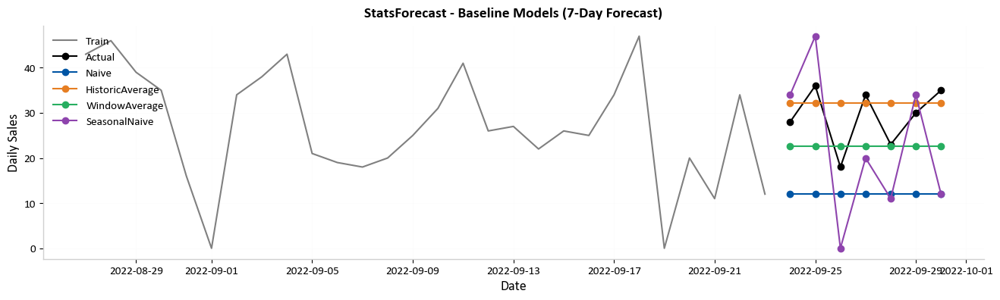

In [153]:
plt.figure(figsize=(16, 4))

plt.plot(
    sf_train["ds"].tail(28),
    sf_train["y"].tail(28),
    label="Train",
    color="gray"
)

plt.plot(
    sf_test["ds"],
    sf_test["y"],
    label="Actual",
    color="black",
    marker="o"
)

for model_name in model_names:
    plt.plot(
        sf_preds["ds"],
        sf_preds[model_name],
        marker="o",
        label=model_name
    )

plt.title("StatsForecast - Baseline Models (7-Day Forecast)")
plt.xlabel("Date")
plt.ylabel("Daily Sales")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#### 6.3.4.3 Auto ARIMA (Non-Seasonal)

In [145]:
from statsforecast.models import AutoARIMA

models_arima = [
    AutoARIMA(
        seasonal=False,
        alias="AutoARIMA"
    )
]

sf_arima = StatsForecast(models=models_arima, freq="D")
sf_arima.fit(df=sf_train)

arima_preds = sf_arima.predict(h=forecast_horizon_sf)
arima_preds

,unique_id,ds,AutoARIMA
0,BAGUETTE,2022-09-24,31.993512
1,BAGUETTE,2022-09-25,27.865637
2,BAGUETTE,2022-09-26,21.218742
3,BAGUETTE,2022-09-27,13.922881
4,BAGUETTE,2022-09-28,15.029813
5,BAGUETTE,2022-09-29,18.381430
6,BAGUETTE,2022-09-30,24.540426


In [146]:
sf_arima.fitted_[0, 0].model_

{'coef': {'ar1': np.float64(0.3909635656257688),
  'ar2': np.float64(-0.46480824636689616),
  'ar3': np.float64(-0.3822100701842122),
  'ar4': np.float64(-0.2603715146665293),
  'ar5': np.float64(-0.2044473675130637),
  'ma1': np.float64(-1.0869483006657583),
  'ma2': np.float64(0.7936634992143577)},
 'sigma2': np.float64(145.62765932525292),
 'var_coef': array([[ 4.51529831e-03,  8.95324715e-04,  1.91186554e-03,
          1.50166265e-03,  5.18619889e-04,  0.00000000e+00,
          0.00000000e+00],
        [ 8.95324715e-04,  3.01725001e-03, -2.18053389e-05,
          1.39789423e-04,  4.37662650e-04,  0.00000000e+00,
          0.00000000e+00],
        [ 1.91186554e-03, -2.18053389e-05,  2.09607201e-03,
         -6.13568107e-04,  5.89277484e-04,  0.00000000e+00,
          0.00000000e+00],
        [ 1.50166265e-03,  1.39789423e-04, -6.13568107e-04,
          1.96059690e-03, -6.76952024e-04,  0.00000000e+00,
          0.00000000e+00],
        [ 5.18619889e-04,  4.37662650e-04,  5.89277484e

In [148]:
arima_eval = sf_test.merge(
    arima_preds,
    on=["unique_id", "ds"],
    how="inner"
)

arima_metrics = evaluate_forecast(
    actual=arima_eval["y"],
    predicted=arima_eval["AutoARIMA"],
    train=sf_train["y"],
    seasonal_period=7
)

arima_summary = pd.DataFrame([arima_metrics], index=["AutoARIMA"]).reset_index(names="model")
arima_summary

,model,MAE,RMSE,MAPE,MASE
0,AutoARIMA,9.353153,10.713708,31.008043,0.922857


In [149]:
sf_comparison = pd.concat([baseline_summary, arima_summary], ignore_index=True).sort_values("MAE").reset_index(drop=True)
sf_comparison

,model,MAE,RMSE,MAPE,MASE
0,HistoricAverage,5.455193,6.904419,23.565646,0.538253
1,WindowAverage,7.877551,9.032820,25.405011,0.777263
2,AutoARIMA,9.353153,10.713708,31.008043,0.922857
3,SeasonalNaive,12.571429,13.969354,46.340304,1.240398
4,Naive,17.142857,18.228706,56.484159,1.691452


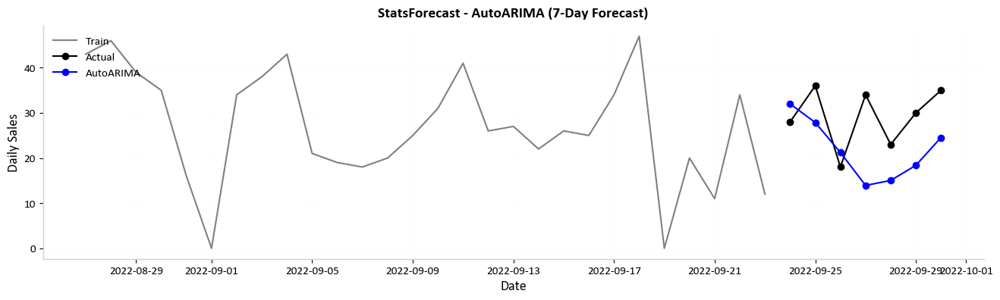

In [152]:
plt.figure(figsize=(16, 4))

plt.plot(
    sf_train["ds"].tail(28),
    sf_train["y"].tail(28),
    label="Train",
    color="gray"
)

plt.plot(
    sf_test["ds"],
    sf_test["y"],
    label="Actual",
    color="black",
    marker="o"
)

plt.plot(
    arima_preds["ds"],
    arima_preds["AutoARIMA"],
    label="AutoARIMA",
    color="blue",
    marker="o"
)

plt.title("StatsForecast - AutoARIMA (7-Day Forecast)")
plt.xlabel("Date")
plt.ylabel("Daily Sales")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#### 6.3.4.4 Auto ARIMA (Seasonal)

In [154]:
models_sarima = [
    AutoARIMA(
        seasonal=True,
        season_length=7,
        alias="AutoSARIMA"
    )
]

sf_sarima = StatsForecast(models=models_sarima, freq="D")
sf_sarima.fit(df=sf_train)

sarima_preds = sf_sarima.predict(h=forecast_horizon_sf)
sarima_preds

,unique_id,ds,AutoSARIMA
0,BAGUETTE,2022-09-24,28.657114
1,BAGUETTE,2022-09-25,42.182373
2,BAGUETTE,2022-09-26,20.013652
3,BAGUETTE,2022-09-27,18.646490
4,BAGUETTE,2022-09-28,16.114925
5,BAGUETTE,2022-09-29,21.288019
6,BAGUETTE,2022-09-30,22.660124


In [155]:
sarima_eval = sf_test.merge(
    sarima_preds,
    on=["unique_id", "ds"],
    how="inner"
)

sarima_metrics = evaluate_forecast(
    actual=sarima_eval["y"],
    predicted=sarima_eval["AutoSARIMA"],
    train=sf_train["y"],
    seasonal_period=7
)

sarima_summary = pd.DataFrame([sarima_metrics], index=["AutoSARIMA"]).reset_index(names="model")
sarima_summary

,model,MAE,RMSE,MAPE,MASE
0,AutoSARIMA,7.449083,8.89634,24.299467,0.734987


In [156]:
sf_comparison = pd.concat([baseline_summary, arima_summary, sarima_summary], ignore_index=True).sort_values("MAE").reset_index(drop=True)
sf_comparison

,model,MAE,RMSE,MAPE,MASE
0,HistoricAverage,5.455193,6.904419,23.565646,0.538253
1,AutoSARIMA,7.449083,8.896340,24.299467,0.734987
2,WindowAverage,7.877551,9.032820,25.405011,0.777263
3,AutoARIMA,9.353153,10.713708,31.008043,0.922857
4,SeasonalNaive,12.571429,13.969354,46.340304,1.240398
5,Naive,17.142857,18.228706,56.484159,1.691452


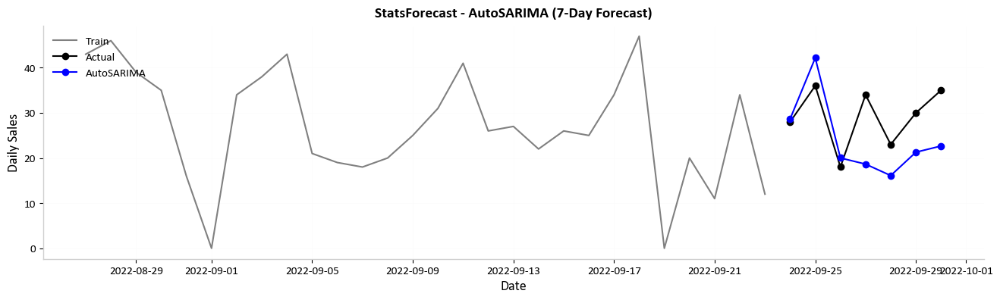

In [158]:
plt.figure(figsize=(16, 4))

plt.plot(
    sf_train["ds"].tail(28),
    sf_train["y"].tail(28),
    label="Train",
    color="gray"
)

plt.plot(
    sf_test["ds"],
    sf_test["y"],
    label="Actual",
    color="black",
    marker="o"
)

plt.plot(
    sarima_preds["ds"],
    sarima_preds["AutoSARIMA"],
    label="AutoSARIMA",
    color="blue",
    marker="o"
)

plt.title("StatsForecast - AutoSARIMA (7-Day Forecast)")
plt.xlabel("Date")
plt.ylabel("Daily Sales")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

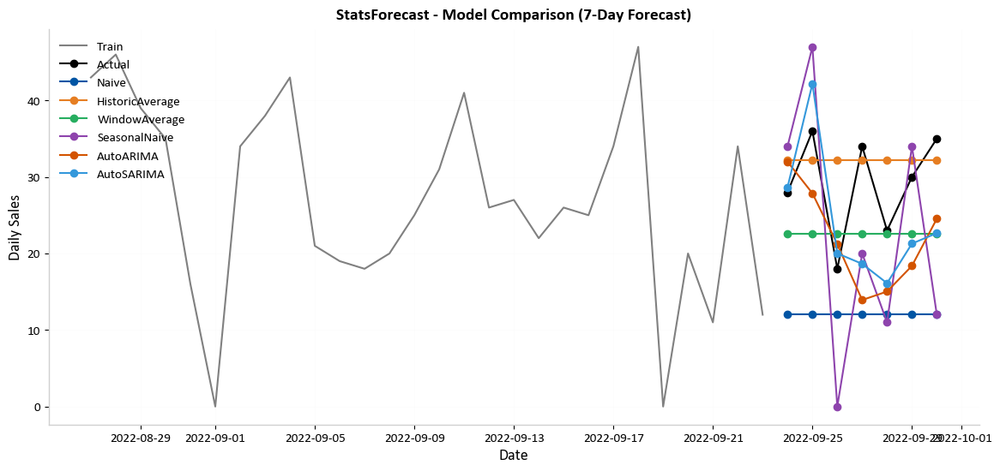

In [159]:
all_preds = sf_preds.merge(
    arima_preds,
    on=["unique_id", "ds"]
).merge(
    sarima_preds,
    on=["unique_id", "ds"]
)

model_names = [
    "Naive",
    "HistoricAverage",
    "WindowAverage",
    "SeasonalNaive",
    "AutoARIMA",
    "AutoSARIMA"
]

plt.figure(figsize=(14, 6))

plt.plot(
    sf_train["ds"].tail(28),
    sf_train["y"].tail(28),
    label="Train",
    color="gray"
)

plt.plot(
    sf_test["ds"],
    sf_test["y"],
    label="Actual",
    color="black",
    marker="o"
)

for model_name in model_names:
    plt.plot(
        all_preds["ds"],
        all_preds[model_name],
        marker="o",
        label=model_name
    )

plt.title("StatsForecast - Model Comparison (7-Day Forecast)")
plt.xlabel("Date")
plt.ylabel("Daily Sales")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#### 6.3.4.5 Rolling Time-Series Cross Validation

In [162]:
from statsforecast import StatsForecast
from statsforecast.models import (
    Naive,
    HistoricAverage,
    WindowAverage,
    SeasonalNaive,
    AutoARIMA
)

models_cv = [
    Naive(),
    HistoricAverage(),
    WindowAverage(window_size=7),
    SeasonalNaive(season_length=7),
    AutoARIMA(
        seasonal=False,
        alias="AutoARIMA"
    ),
    AutoARIMA(
        seasonal=True,
        season_length=7,
        alias="AutoSARIMA"
    )
]

In [163]:
sf_cv = StatsForecast(models=models_cv, freq="D")

cv_df = sf_cv.cross_validation(
    df=sf_train,
    h=forecast_horizon_sf,
    n_windows=10,  # <- DEFINE THIS MANUALLY
    step_size=forecast_horizon_sf,
    refit=True
)

In [164]:
cv_df.head()

,unique_id,ds,cutoff,y,Naive,HistoricAverage,WindowAverage,SeasonalNaive,AutoARIMA,AutoSARIMA
0,BAGUETTE,2022-07-16,2022-07-15,99.0,79.0,30.597143,60.285714,33.0,58.084958,65.900837
1,BAGUETTE,2022-07-17,2022-07-15,94.0,79.0,30.597143,60.285714,57.0,51.118923,77.570289
2,BAGUETTE,2022-07-18,2022-07-15,50.0,79.0,30.597143,60.285714,69.0,48.798791,61.820612
3,BAGUETTE,2022-07-19,2022-07-15,36.0,79.0,30.597143,60.285714,56.0,48.026040,53.627425
4,BAGUETTE,2022-07-20,2022-07-15,47.0,79.0,30.597143,60.285714,51.0,47.768665,49.406318


In [165]:
model_names = [
    "Naive",
    "HistoricAverage",
    "WindowAverage",
    "SeasonalNaive",
    "AutoARIMA",
    "AutoSARIMA"
]

cv_results = []

for cutoff, fold_df in cv_df.groupby("cutoff"):

    cv_train = sf_train.loc[sf_train["ds"] <= cutoff, "y"]

    for model_name in model_names:

        metrics = evaluate_forecast(
            actual=fold_df["y"],
            predicted=fold_df[model_name],
            train=cv_train,
            seasonal_period=7
        )

        cv_results.append({
            "cutoff": cutoff,
            "model": model_name,
            **metrics
        })

cv_results = pd.DataFrame(cv_results)

In [166]:
cv_results.head()

,cutoff,model,MAE,RMSE,MAPE,MASE
0,2022-07-15,Naive,31.285714,32.822031,69.583394,3.203830
1,2022-07-15,HistoricAverage,27.117143,36.871988,38.320762,2.776945
2,2022-07-15,WindowAverage,23.265306,25.116057,42.947389,2.382496
3,2022-07-15,SeasonalNaive,32.000000,36.940106,58.355614,3.276976
4,2022-07-15,AutoARIMA,16.447053,23.335202,24.143384,1.684269


In [168]:
cv_results['cutoff'].value_counts()

cutoff
2022-07-15    6
2022-07-22    6
2022-07-29    6
2022-08-05    6
2022-08-12    6
2022-08-19    6
2022-08-26    6
2022-09-02    6
2022-09-09    6
2022-09-16    6
Name: count, dtype: int64

In [167]:
cv_summary = (
    cv_results
    .groupby("model")
    .agg({
        "MAE": "mean",
        "RMSE": "mean",
        "MAPE": "mean",
        "MASE": "mean"
    })
    .sort_values("MAE")
    .reset_index()
)

cv_summary

,model,MAE,RMSE,MAPE,MASE
0,AutoSARIMA,10.365077,12.331746,26.469965,1.032666
1,AutoARIMA,10.566569,13.372310,24.648061,1.052816
2,WindowAverage,12.302041,14.446091,32.371218,1.226485
3,SeasonalNaive,13.057143,15.422286,33.396712,1.304253
4,Naive,14.600000,16.835225,35.819405,1.457399
5,HistoricAverage,19.686980,22.805629,42.513009,1.961089


In [169]:
cv_stability = (
    cv_results
    .groupby("model")
    .agg(
        MAE_mean=("MAE", "mean"),
        MAE_std=("MAE", "std"),
        MAE_min=("MAE", "min"),
        MAE_max=("MAE", "max")
    )
    .sort_values("MAE_mean")
    .reset_index()
)

cv_stability

,model,MAE_mean,MAE_std,MAE_min,MAE_max
0,AutoSARIMA,10.365077,4.735333,3.714757,17.721141
1,AutoARIMA,10.566569,4.348226,3.685716,16.447053
2,WindowAverage,12.302041,5.866824,3.755102,23.265306
3,SeasonalNaive,13.057143,7.622083,4.571429,32.000000
4,Naive,14.600000,7.921039,4.142857,31.285714
5,HistoricAverage,19.686980,8.603229,6.528525,32.925220


#### 6.3.4.6 Model Selection and Evaluation

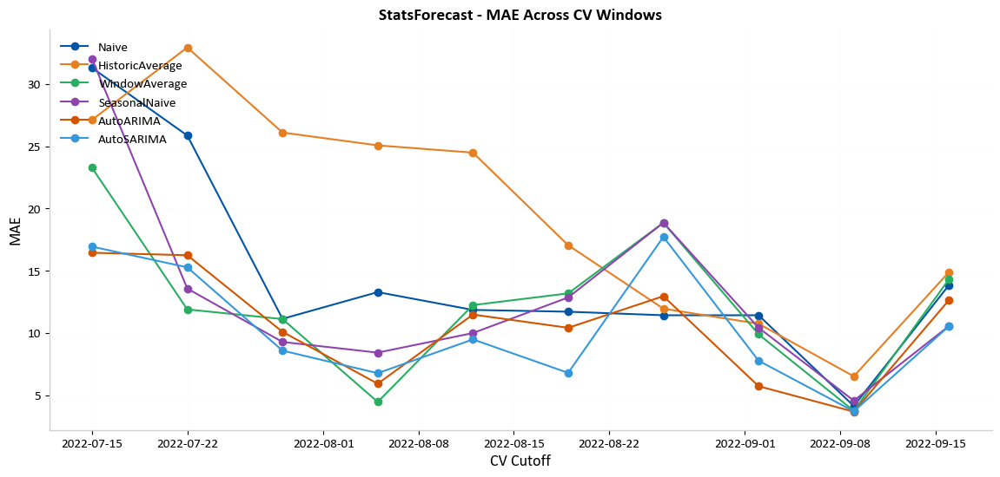

In [170]:
plt.figure(figsize=(14, 6))

for model_name in model_names:
    temp = cv_results[cv_results["model"] == model_name]

    plt.plot(
        temp["cutoff"],
        temp["MAE"],
        marker="o",
        label=model_name
    )

plt.title("StatsForecast - MAE Across CV Windows")
plt.xlabel("CV Cutoff")
plt.ylabel("MAE")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [172]:
model_info = sf_sarima.fitted_[0, 0].model_

print("Selected SARIMA order:", model_info["arma"])
print("Coefficients:", model_info["coef"])
print("AIC:", model_info["aic"])
print("BIC:", model_info["bic"])
print("Residual variance:", model_info["sigma2"])

Selected SARIMA order: (2, 1, 1, 1, 7, 0, 1)
Coefficients: {'ar1': np.float64(1.1887938258509445), 'ar2': np.float64(-0.21409727291403954), 'ma1': np.float64(-0.8039187032592643), 'sar1': np.float64(0.07760268579192015), 'sma1': np.float64(-0.8988662220543505)}
AIC: 4695.7180008610885
BIC: 4722.325279973813
Residual variance: 107.00660484279629


SARIMA(2, 0, 1)(1, 1, 1, 7)
- Parameter	| Value	| Meaning
- p	2	2 non-seasonal AR terms
- d	0	No regular differencing
- q	1	1 non-seasonal MA term
- P	1	1 seasonal AR term
- D	1	1 seasonal differencing
- Q	1	1 seasonal MA term
- m	7	Weekly seasonality

In [175]:
print("Training observations:", len(sf_train))
print("Model observations:", model_info["nobs"])
print("Difference:", len(sf_train) - model_info["nobs"])

Training observations: 630
Model observations: 623
Difference: 7


In [176]:
best_model_name = "AutoSARIMA"

final_metrics = evaluate_forecast(
    actual=sf_test["y"],
    predicted=sarima_preds["AutoSARIMA"],
    train=sf_train["y"],
    seasonal_period=7
)

pd.DataFrame([final_metrics], index=[best_model_name])

,MAE,RMSE,MAPE,MASE
AutoSARIMA,7.449083,8.89634,24.299467,0.734987


### 6.3.5 Prediction Interval

In [177]:
sarima_preds_pi = sf_sarima.predict(h=forecast_horizon_sf, level=[80, 95])
sarima_preds_pi

,unique_id,ds,AutoSARIMA,AutoSARIMA-lo-95,AutoSARIMA-lo-80,AutoSARIMA-hi-80,AutoSARIMA-hi-95
0,BAGUETTE,2022-09-24,28.657114,8.382463,15.400232,41.913995,48.931764
1,BAGUETTE,2022-09-25,42.182373,20.457928,27.977522,56.387225,63.906819
2,BAGUETTE,2022-09-26,20.013652,-2.264415,5.446807,34.580497,42.291719
3,BAGUETTE,2022-09-27,18.646490,-4.023439,3.823420,33.469560,41.316419
4,BAGUETTE,2022-09-28,16.114925,-6.893550,1.070492,31.159358,39.123400
5,BAGUETTE,2022-09-29,21.288019,-2.028301,6.042296,36.533741,44.604339
6,BAGUETTE,2022-09-30,22.660124,-0.939752,7.228994,38.091253,46.259999


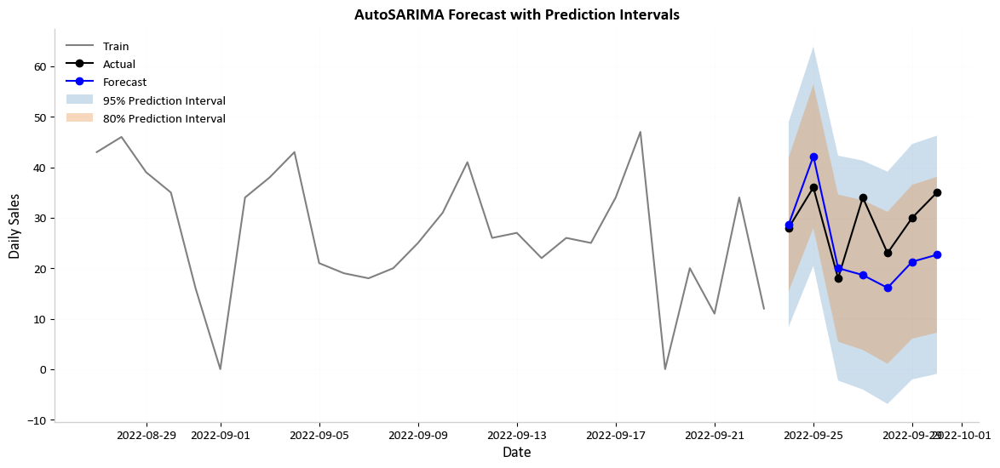

In [178]:
plt.figure(figsize=(14, 6))

plt.plot(sf_train["ds"].tail(28), sf_train["y"].tail(28), label="Train", color="gray")
plt.plot(sf_test["ds"], sf_test["y"], label="Actual", color="black", marker="o")

plt.plot(sarima_preds_pi["ds"], sarima_preds_pi["AutoSARIMA"], label="Forecast", color="blue", marker="o")
plt.fill_between(sarima_preds_pi["ds"], sarima_preds_pi["AutoSARIMA-lo-95"], sarima_preds_pi["AutoSARIMA-hi-95"], 
                 alpha=0.2, label="95% Prediction Interval")
plt.fill_between(sarima_preds_pi["ds"], sarima_preds_pi["AutoSARIMA-lo-80"], sarima_preds_pi["AutoSARIMA-hi-80"],
                 alpha=0.3, label="80% Prediction Interval")

plt.title("AutoSARIMA Forecast with Prediction Intervals")
plt.xlabel("Date")
plt.ylabel("Daily Sales")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [179]:
pi_eval = sf_test.merge(
    sarima_preds_pi,
    on=["unique_id", "ds"],
    how="inner"
)

coverage_results = []

for level in [80, 95]:

    lower = pi_eval[f"AutoSARIMA-lo-{level}"]
    upper = pi_eval[f"AutoSARIMA-hi-{level}"]

    coverage = (
        (pi_eval["y"] >= lower) &
        (pi_eval["y"] <= upper)
    ).mean() * 100

    coverage_results.append({
        "confidence_level": f"{level}%",
        "coverage": coverage,
        "average_interval_width": (upper - lower).mean()
    })

coverage_summary = pd.DataFrame(coverage_results)
coverage_summary

,confidence_level,coverage,average_interval_width
0,80%,85.714286,29.306552
1,95%,100.000000,44.820504


In [180]:
import joblib

joblib.dump(sf_sarima, "model_autosarima.pkl")

['model_autosarima.pkl']

# 7. Machine Learning Forecasting

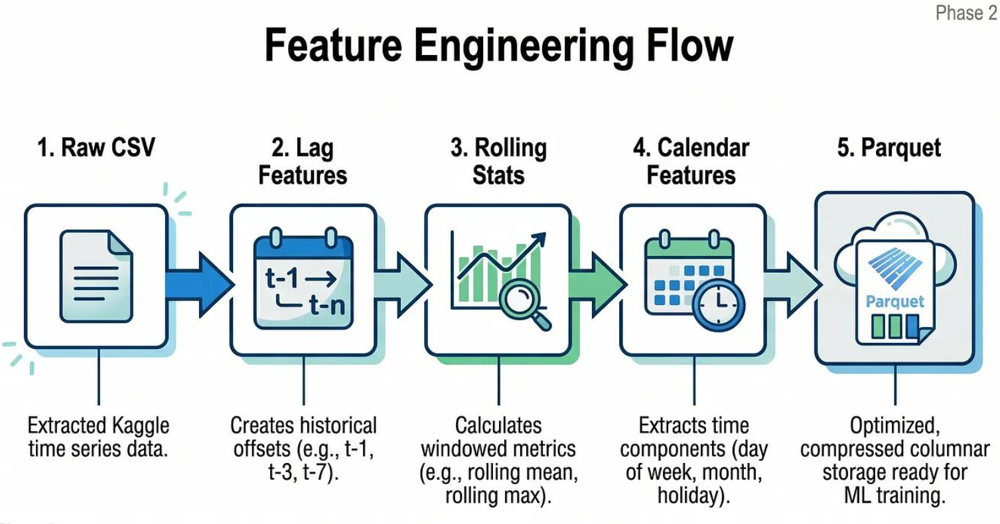

*Goal*: Convert a time series problem into a supervised ML problem and compare against statistical forecasting (ARIMA/SARIMA).

There are two important forecasting scenarios.

**One-step forecasting**
- Predict only the next observation.

**Multi-Step Forecasting**

*Approach	| Explanation*
- Recursive:	Predict one day, then use the prediction to predict the next
- Direct:	Train separate models for each forecast horizon
- Multi-output:	Predict all future days simultaneously

## 7.1 Feature Preparation

In [181]:
print(data.shape)
print(data.columns.tolist())

(637, 41)
['y', 'day_of_week', 'month', 'year', 'day', 'day_of_year', 'week_of_year', 'quarter', 'is_weekend', 'is_payweek', 'is_month_start', 'is_month_end', 'day_sin', 'day_cos', 'is_public_holiday', 'public_holiday_name', 'is_special_event', 'special_event_name', 'lag_1', 'lag_2', 'lag_3', 'lag_7', 'lag_14', 'lag_21', 'lag_28', 'rolling_mean_3', 'rolling_std_3', 'rolling_min_3', 'rolling_max_3', 'rolling_mean_7', 'rolling_std_7', 'rolling_min_7', 'rolling_max_7', 'rolling_mean_14', 'rolling_std_14', 'rolling_min_14', 'rolling_max_14', 'rolling_mean_28', 'rolling_std_28', 'rolling_min_28', 'rolling_max_28']


In [182]:
target_col = "y"
exclude_cols = [target_col]

cols_pred_cat, cols_pred_num = divide_predictors(
    data=data,
    target_col=target_col,
    exclude_cols=exclude_cols,
    categorical_cols=[
        "day_of_week",
        "month",
        "quarter",
        "is_weekend",
        "is_public_holiday",
        "is_special_event",
        "is_payweek",
        "is_month_start",
        "is_month_end"
    ]
)

print("Categorical predictors:", cols_pred_cat)
print("Numerical predictors:", cols_pred_num)

Categorical predictors: ['day_of_week', 'month', 'quarter', 'is_weekend', 'is_payweek', 'is_month_start', 'is_month_end', 'is_public_holiday', 'public_holiday_name', 'is_special_event', 'special_event_name']
Numerical predictors: ['year', 'day', 'day_of_year', 'week_of_year', 'day_sin', 'day_cos', 'lag_1', 'lag_2', 'lag_3', 'lag_7', 'lag_14', 'lag_21', 'lag_28', 'rolling_mean_3', 'rolling_std_3', 'rolling_min_3', 'rolling_max_3', 'rolling_mean_7', 'rolling_std_7', 'rolling_min_7', 'rolling_max_7', 'rolling_mean_14', 'rolling_std_14', 'rolling_min_14', 'rolling_max_14', 'rolling_mean_28', 'rolling_std_28', 'rolling_min_28', 'rolling_max_28']


In [184]:
len(cols_pred_cat), len(cols_pred_num)

(11, 29)

In [185]:
data[cols_pred_cat].isna().sum()

day_of_week              0
month                    0
quarter                  0
is_weekend               0
is_payweek               0
is_month_start           0
is_month_end             0
is_public_holiday        0
public_holiday_name    619
is_special_event         0
special_event_name     637
dtype: int64

In [191]:
data_ml = data.copy()

# Fill missing categorical event names
name_cols = ["public_holiday_name", "special_event_name"]
data_ml[name_cols] = data_ml[name_cols].fillna("None")

# One-hot encode nominal categorical features
onehot_cols = [i for i in cols_pred_cat if "is_" not in i]

data_ml = pd.get_dummies(
    data_ml,
    columns=onehot_cols,
    drop_first=True,
    dtype=int
)

In [192]:
data_ml.columns.tolist()

['y',
 'year',
 'day',
 'day_of_year',
 'week_of_year',
 'is_weekend',
 'is_payweek',
 'is_month_start',
 'is_month_end',
 'day_sin',
 'day_cos',
 'is_public_holiday',
 'is_special_event',
 'lag_1',
 'lag_2',
 'lag_3',
 'lag_7',
 'lag_14',
 'lag_21',
 'lag_28',
 'rolling_mean_3',
 'rolling_std_3',
 'rolling_min_3',
 'rolling_max_3',
 'rolling_mean_7',
 'rolling_std_7',
 'rolling_min_7',
 'rolling_max_7',
 'rolling_mean_14',
 'rolling_std_14',
 'rolling_min_14',
 'rolling_max_14',
 'rolling_mean_28',
 'rolling_std_28',
 'rolling_min_28',
 'rolling_max_28',
 'day_of_week_1',
 'day_of_week_2',
 'day_of_week_3',
 'day_of_week_4',
 'day_of_week_5',
 'day_of_week_6',
 'month_2',
 'month_3',
 'month_4',
 'month_5',
 'month_6',
 'month_7',
 'month_8',
 'month_9',
 'month_10',
 'month_11',
 'month_12',
 'quarter_2',
 'quarter_3',
 'quarter_4',
 'public_holiday_name_Ascension',
 'public_holiday_name_Assomption',
 'public_holiday_name_Fête de la Victoire',
 'public_holiday_name_Fête du Travail',


In [194]:
data_ml.shape

(637, 67)

In [195]:
# define predictors and target
X = data_ml.drop(columns=["y"])
y = data_ml["y"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (637, 66)
y shape: (637,)


In [197]:
# Determine test starting date
test_start = data_ml.index.max() - pd.Timedelta(days=test_period - 1)

# Chronological split
train = data_ml.loc[data_ml.index < test_start].copy()
test = data_ml.loc[data_ml.index >= test_start].copy()
train.shape, test.shape

((547, 67), (90, 67))

In [198]:
print("Train:", train.index.min(), "to", train.index.max())
print("Test:", test.index.min(), "to", test.index.max())

Train: 2021-01-02 00:00:00 to 2022-07-02 00:00:00
Test: 2022-07-03 00:00:00 to 2022-09-30 00:00:00


In [199]:
data_ml.isna().sum().sum()

np.int64(284)

In [200]:
missing = (
    data_ml.isna()
    .sum()
    .loc[lambda x: x > 0]
    .sort_values(ascending=False)
)

missing

lag_28             28
rolling_std_28     28
rolling_mean_28    28
rolling_max_28     28
rolling_min_28     28
lag_21             21
lag_14             14
rolling_mean_14    14
rolling_std_14     14
rolling_min_14     14
rolling_max_14     14
rolling_mean_7      7
rolling_std_7       7
rolling_min_7       7
lag_7               7
rolling_max_7       7
rolling_mean_3      3
lag_3               3
rolling_std_3       3
rolling_min_3       3
rolling_max_3       3
lag_2               2
lag_1               1
dtype: int64

In [202]:
# Drop rows with missing values from lag and rolling features
data_ml = data_ml.dropna().copy()

# Verify
print("Shape:", data_ml.shape)
print("Missing values:", data_ml.isna().sum().sum())

Shape: (609, 67)
Missing values: 0


In [203]:
test_start = data_ml.index.max() - pd.Timedelta(days=test_period - 1)

train = data_ml.loc[data_ml.index < test_start].copy()
test = data_ml.loc[data_ml.index >= test_start].copy()

print("Train:", train.shape)
print("Test:", test.shape)

Train: (519, 67)
Test: (90, 67)


## 7.2 One Step Ahead Forecasting - Linear Regression

Understand the basic regression forecasting approach.
- Define target (y) and predictors (X)
- Fit Linear Regression
- Generate one-step-ahead predictions
- Evaluate model performance
- Analyze regression coefficients

In [204]:
target_col = "y"

X_train = train.drop(columns=[target_col])
y_train = train[target_col]

X_test = test.drop(columns=[target_col])
y_test = test[target_col]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (519, 66)
X_test: (90, 66)


In [205]:
from sklearn.linear_model import LinearRegression

# Initialize model
lr_model = LinearRegression()

# Fit model
lr_model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [206]:
y_pred = pd.Series(
    lr_model.predict(X_test),
    index=y_test.index,
    name="Linear Regression"
)

In [207]:
lr_metrics = evaluate_forecast(
    actual=y_test,
    predicted=y_pred,
    train=y_train
)

pd.DataFrame([lr_metrics], index=["Linear Regression"])

,MAE,RMSE,MAPE,MASE
Linear Regression,9.908485,12.870149,24.156926,1.00933


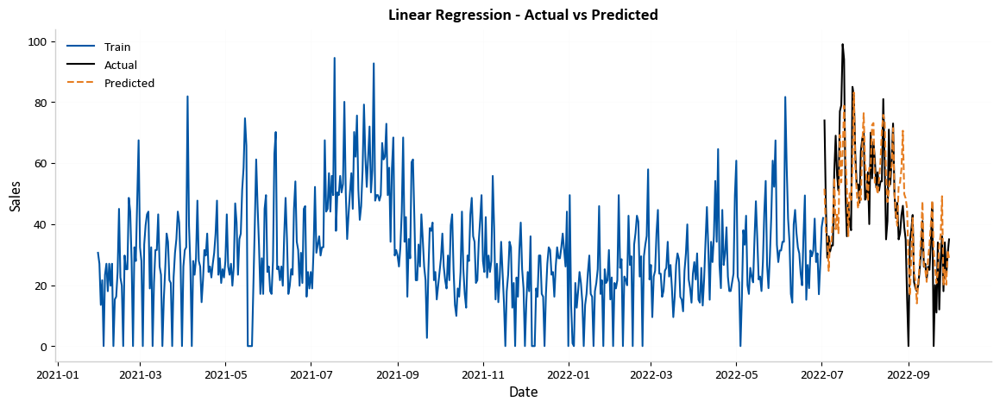

In [208]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(y_train.index, y_train, label="Train")
plt.plot(y_test.index, y_test, label="Actual", color="black")
plt.plot(y_pred.index, y_pred, label="Predicted", linestyle="--")

plt.title("Linear Regression - Actual vs Predicted")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [209]:
# Prediction error
residuals = y_test - y_pred

print("Mean Error:", residuals.mean())
print("Min Error:", residuals.min())
print("Max Error:", residuals.max())

# Check negative predictions
print("Negative predictions:", (y_pred < 0).sum())

Mean Error: -1.2441243308118817
Min Error: -31.608387270500202
Max Error: 35.00846021210543
Negative predictions: 0


In [210]:
error_df = pd.DataFrame({
    "actual": y_test,
    "predicted": y_pred,
    "error": residuals,
    "abs_error": residuals.abs()
})

error_df.sort_values("abs_error", ascending=False).head(10)

,actual,predicted,error,abs_error
ds,,,,
2022-07-16,99.0,63.991540,35.008460,35.008460
2022-09-19,0.0,31.608387,-31.608387,31.608387
2022-07-11,69.0,38.296513,30.703487,30.703487
2022-08-31,16.0,45.093971,-29.093971,29.093971
2022-09-01,0.0,28.500053,-28.500053,28.500053
2022-07-23,85.0,57.788650,27.211350,27.211350
2022-07-15,79.0,53.695336,25.304664,25.304664
2022-08-28,46.0,70.622869,-24.622869,24.622869
2022-07-03,74.0,51.613756,22.386244,22.386244


## 7.3 Recursive Multi-Step Forecasting

Use a one-step-ahead model to generate predictions over multiple future periods.
- Train a one-step-ahead regression model
- Understand recursive forecasting
- Generate predictions iteratively
- Feed previous predictions back into lag features
- Evaluate multi-step forecasting performance

## 7.4 Direct Multi-Step Forecasting

Train models to predict multiple future periods directly.
- Create multi-output targets
- Train a multi-output regression model
- Feature selection for each forecast horizon
- Generate predictions for the entire forecast horizon
- Evaluate multi-step forecasting performance

## 7.5 Model Comparison and Evaluation

Compare the different forecasting approaches.
- One-step-ahead Linear Regression
- Recursive Regression
- Direct Multi-Step Regression
- MAE, RMSE, MAPE, and MASE
- Actual vs predicted visualization
- Forecast error across different horizons

# 8. Advanced Forecasting

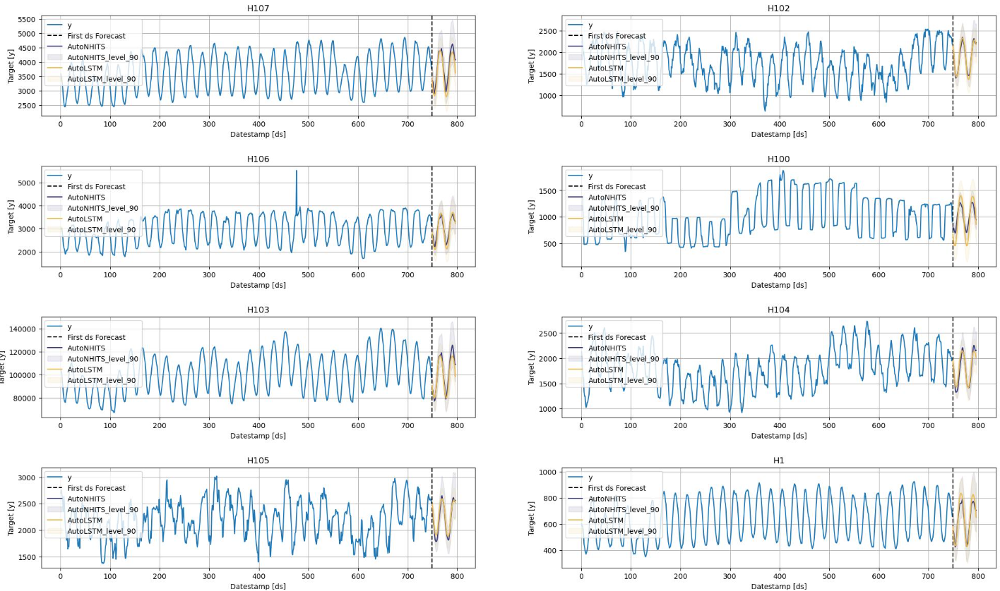

Method:
- Prophet
- Multivariate time series.
- VAR (Vector Autoregression).
- Global vs local forecasting models.
- Deep learning introduction: LSTM, GRU, N-BEATS, Temporal Fusion Transformer.